In [1]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 927.5 kB/s eta 0:00:00


In [2]:
import os, gc, sys, copy, pickle
from pathlib import Path
import glob
from tqdm.auto import tqdm
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor
import math
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from PIL import Image as PILImage
from datasets import Dataset, Image,Features
import warnings
import torch
warnings.filterwarnings("ignore")
tqdm.pandas()
import os
os.environ["WANDB_DISABLED"] = "true"

In [3]:
def seeding(SEED):
    np.random.seed(SEED)
    random.seed(SEED)
    os.environ['PYTHONHASHSEED'] = str(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): 
        torch.cuda.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True
#     os.environ['TF_CUDNN_DETERMINISTIC'] = str(SEED)
#     tf.random.set_seed(SEED)
#     keras.utils.set_random_seed(seed=SEED)
    print('seeding done!!!')

def flush():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

In [4]:

import numpy as np, pandas as pd, cv2

try:
    PHASE1_COORD_CSV = cfg['phase1_coord_csv']
    CROP_PX, MODEL_PX, PHASE1_MPE, TRAIN_JIT = cfg['crop_px'], cfg['model_px'], cfg['phase1_mpe'], cfg['train_jit']
except Exception:
    PHASE1_COORD_CSV = '/kaggle/input/rsna-phase1-coordinates/stage3_coor_with_depth.csv'

CROP_PX    = 96      # crop side, measured on the 256x256 canvas
MODEL_PX   = 256     # crop is resized back to 256x256 -> models / transforms / loss stay identical to baseline
PHASE1_MPE = 6.88    # px @256; emulates Phase 1 error only where a prediction is missing
TRAIN_JIT  = 3.0     # px @256; train-time jitter so the classifier tolerates Phase 1 error

p1 = pd.read_csv(PHASE1_COORD_CSV)
P1_XY = {(r.study_id, r.series_id, r.condition, r.level): (r.x, r.y) for r in p1.itertuples()}
print(f'Phase 1 coordinates loaded: {len(P1_XY):,}')

def crop_around(img, cx, cy, jitter=0.0):
    """img: HxW uint8. (cx, cy) in img pixels. Returns MODEL_PX x MODEL_PX crop centred on (cx, cy)."""
    H, W = img.shape[:2]
    canvas = cv2.resize(img, (MODEL_PX, MODEL_PX), interpolation=cv2.INTER_LINEAR)
    cx, cy = cx * MODEL_PX / W, cy * MODEL_PX / H
    if jitter > 0:
        cx += np.random.normal(0, jitter); cy += np.random.normal(0, jitter)
    half = CROP_PX // 2
    pad = np.pad(canvas, ((half, half), (half, half)), mode='edge')
    x0 = int(np.clip(round(cx), 0, MODEL_PX)); y0 = int(np.clip(round(cy), 0, MODEL_PX))
    patch = pad[y0:y0 + CROP_PX, x0:x0 + CROP_PX]
    return cv2.resize(patch, (MODEL_PX, MODEL_PX), interpolation=cv2.INTER_LINEAR)

def phase1_center(row, W, H):
    """Phase 1 predicted (x, y); falls back to the label + Phase-1-sized error if a prediction is missing."""
    k = (row['study_id'], row['series_id'], row['condition'], row['level'])
    if k in P1_XY:
        return P1_XY[k]
    s = PHASE1_MPE / np.sqrt(2) / MODEL_PX
    return row['x'] + np.random.normal(0, s * W), row['y'] + np.random.normal(0, s * H)

def audit_phase1_coverage(df, label=""):
    """Report how often stage3_coor.csv supplies (x,y) vs label+noise fallback."""
    keys = list(zip(df["study_id"], df["series_id"], df["condition"], df["level"]))
    hit = sum(1 for k in keys if k in P1_XY)
    n = len(keys)
    miss = n - hit
    pct = 100.0 * hit / n if n else 0.0
    print(
        f"Phase 1 CSV coverage{label}: {hit:,}/{n:,} ({pct:.2f}%) from stage3_coor.csv; "
        f"{miss:,} rows use label-centre + noise fallback (MPE={PHASE1_MPE}px @256, not every row)"
    )
    return hit, miss

# Prefer Approach 3 bridge paths from Phase 2 config when available
if "PHASE2_CFG" in globals():
    PHASE1_COORD_CSV = PHASE2_CFG.get("phase1_coord_csv", PHASE1_COORD_CSV)
    CROP_PX = PHASE2_CFG.get("crop_px", CROP_PX)
    MODEL_PX = PHASE2_CFG.get("model_px", MODEL_PX)
    PHASE1_MPE = PHASE2_CFG.get("phase1_mpe_px", PHASE1_MPE)
    TRAIN_JIT = PHASE2_CFG.get("train_jitter_px", TRAIN_JIT)


### Phase 2 bridge configuration



In [5]:
import os
import pickle

CONFIG_CANDIDATES = [
    "/kaggle/working/bridge_config/phase2_bridge_config.pkl",
    "bridge_config/phase2_bridge_config.pkl",
    "/kaggle/input/rsna-phase1-coordinates/phase2_bridge_config.pkl",
]

def load_phase2_config():
    for path in CONFIG_CANDIDATES:
        if os.path.isfile(path):
            with open(path, "rb") as f:
                cfg = pickle.load(f)
            print(f"Loaded Phase 2 config: {path}")
            return cfg, path
    raise FileNotFoundError("phase2_bridge_config.pkl not found")

PHASE2_CFG, PHASE2_CFG_PATH = load_phase2_config()
PHASE1_COORD_CSV = PHASE2_CFG["phase1_coord_csv"]
PHASE1_DEPTH_CSV = PHASE2_CFG.get("phase1_depth_csv", PHASE1_COORD_CSV)
CROP_PX = PHASE2_CFG["crop_px"]
MODEL_PX = PHASE2_CFG["model_px"]
PHASE1_MPE = PHASE2_CFG["phase1_mpe_px"]
TRAIN_JIT = PHASE2_CFG["train_jitter_px"]
USE_CLASS_BALANCE = bool(PHASE2_CFG.get("use_class_balance", True))
USE_WEIGHTED_SAMPLER = bool(PHASE2_CFG.get("use_weighted_sampler", True))

print(
    f"bridge_source={PHASE2_CFG.get('phase1_bridge_source')} "
    f"crop_px={CROP_PX} model_px={MODEL_PX} "
    f"balance={USE_CLASS_BALANCE} sampler={USE_WEIGHTED_SAMPLER}"
)
print(f"coord_csv={PHASE1_COORD_CSV}")
print(f"depth_csv={PHASE1_DEPTH_CSV}")


Loaded Phase 2 config: bridge_config/phase2_bridge_config.pkl
bridge_source=approach3 crop_px=96 model_px=256 balance=True sampler=True
coord_csv=/kaggle/input/rsna-phase1-coordinates/stage3_coor.csv
depth_csv=/kaggle/input/rsna-phase1-coordinates/stage3_depth_instance.csv


### Phase 1 instance map

Builds `(study_id, series_id, condition, level) → instance_number` from the Approach 3 depth export for crop / slice selection.

In [6]:
import os
import pandas as pd

depth_csv = PHASE1_DEPTH_CSV if "PHASE1_DEPTH_CSV" in globals() else PHASE2_CFG["phase1_depth_csv"]
coord_csv = PHASE1_COORD_CSV if "PHASE1_COORD_CSV" in globals() else PHASE2_CFG["phase1_coord_csv"]

depth_df = pd.read_csv(depth_csv) if os.path.isfile(depth_csv) else pd.read_csv(coord_csv)
need = ["study_id", "series_id", "condition", "level", "instance_number"]
for c in need:
    if c not in depth_df.columns:
        raise KeyError(f"Depth export missing {c}")

P1_INSTANCE = {
    (int(r.study_id), int(r.series_id), str(r.condition), str(r.level)): int(r.instance_number)
    for r in depth_df.itertuples()
}
print(
    f"Phase 1 instance keys={len(P1_INSTANCE)} "
    f"from {depth_csv if os.path.isfile(depth_csv) else coord_csv}"
)

def phase1_instance_number(row):
    """Return Phase 1 Approach-3 instance_number for a condition/level row."""
    key = (
        int(row["study_id"]),
        int(row["series_id"]),
        str(row["condition"]),
        str(row["level"]),
    )
    return P1_INSTANCE.get(key)


Phase 1 instance keys=48692 from /kaggle/input/rsna-phase1-coordinates/stage3_depth_instance.csv
helper=phase1_instance_number ready


### Use Phase‑1 `instance_number` (Approach 3) in crops

Helper for slice selection from Phase-1 `instance_number`; `phase1_center` still supplies `xy`.

In [7]:

# Consume Approach-3 instance_number for slice selection (xy still from phase1_center / P1_XY)
import numpy as np

def phase1_instance(row, n_slices):
    """Return 0-based slice index from Phase-1 export; mid-series fallback."""
    inst = row["instance_number"] if hasattr(row, "__getitem__") and "instance_number" in getattr(row, "index", []) else None
    if inst is None and isinstance(row, dict):
        inst = row.get("instance_number")
    try:
        if inst is not None and not (isinstance(inst, float) and np.isnan(inst)):
            # DICOM instance_number is often 1-based; clamp into [0, n_slices-1]
            idx = int(inst) - 1 if int(inst) >= 1 else int(inst)
            return int(np.clip(idx, 0, max(n_slices - 1, 0)))
    except Exception:
        pass
    return int(n_slices // 2)

print("phase1_instance() helper registered — uses Approach-3 instance_number when present")
print("Falls back to series mid-slice if instance missing")


phase1_instance() helper registered — uses Approach-3 instance_number when present
Falls back to series mid-slice if instance missing


In [8]:
df_train = pd.read_csv("/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/train.csv")
df_train_desc = pd.read_csv("/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/train_label_coordinates.csv")
df_train_desc['image_path'] = "/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/train_images/" + df_train_desc['study_id'].astype(str) +"/"+ df_train_desc['series_id'].astype(str) + "/"+ df_train_desc['instance_number'].astype(str) + ".dcm"
df_train_desc.sample(5)

,study_id,series_id,instance_number,condition,level,x,y,image_path
2731,228290246,2749944059,8,Spinal Canal Stenosis,L5/S1,312.579710,368.463768,/kaggle/input/rsna-2024-lumbar-spine-degenerat...
5464,478913051,3560850751,13,Left Neural Foraminal Narrowing,L2/L3,184.285965,120.698254,/kaggle/input/rsna-2024-lumbar-spine-degenerat...
2115,182843007,780324614,15,Right Subarticular Stenosis,L4/L5,306.678636,326.242161,/kaggle/input/rsna-2024-lumbar-spine-degenerat...
45319,3985825195,3514821988,2,Left Neural Foraminal Narrowing,L5/S1,311.811406,356.646116,/kaggle/input/rsna-2024-lumbar-spine-degenerat...
16843,1506063459,677114139,10,Left Neural Foraminal Narrowing,L2/L3,286.343324,180.664850,/kaggle/input/rsna-2024-lumbar-spine-degenerat...


In [9]:
df_train_melted = df_train.melt(id_vars=['study_id'], var_name='condition_level', value_name='value')

# Split the 'condition_level' column to extract 'condition' and 'level'
df_train_melted[['conditions', 'level']] = df_train_melted['condition_level'].str.rsplit('_', n=2, expand=True).iloc[:, 1:]
df_train_melted['condition'] = df_train_melted['condition_level'].apply(lambda x: '_'.join(x.split('_')[:-2])).str.replace("_"," ").str.title()
df_train_melted['level'] = df_train_melted['conditions'].str.upper() +"/"+ df_train_melted['level'].str.upper()
# Remove the original 'condition_level' column
df_train_melted = df_train_melted.drop(columns=['condition_level', 'conditions'])

# Rename columns for clarity
df_train_melted = df_train_melted.rename(columns={'value': 'severity'})
df_train_melted.sample(5)

,study_id,severity,level,condition
1561,3396002092,Normal/Mild,L1/L2,Spinal Canal Stenosis
3413,3143299204,Normal/Mild,L2/L3,Spinal Canal Stenosis
24195,1095894979,Normal/Mild,L3/L4,Right Neural Foraminal Narrowing
18153,833869440,Moderate,L5/S1,Left Neural Foraminal Narrowing
43954,1115952008,Moderate,L3/L4,Right Subarticular Stenosis


In [10]:
df_final = df_train_desc.merge(df_train_melted, on = ["study_id","level","condition"],how = "left")
df_final
audit_phase1_coverage(df_final, label=' (training table)')


,study_id,series_id,instance_number,condition,level,x,y,image_path,severity
0,4003253,702807833,8,Spinal Canal Stenosis,L1/L2,322.831858,227.964602,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
1,4003253,702807833,8,Spinal Canal Stenosis,L2/L3,320.571429,295.714286,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
2,4003253,702807833,8,Spinal Canal Stenosis,L3/L4,323.030303,371.818182,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
3,4003253,702807833,8,Spinal Canal Stenosis,L4/L5,335.292035,427.327434,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
4,4003253,702807833,8,Spinal Canal Stenosis,L5/S1,353.415929,483.964602,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
...,...,...,...,...,...,...,...,...,...
48687,4290709089,4237840455,11,Left Neural Foraminal Narrowing,L1/L2,219.465940,97.831063,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
48688,4290709089,4237840455,12,Left Neural Foraminal Narrowing,L2/L3,205.340599,140.207084,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
48689,4290709089,4237840455,12,Left Neural Foraminal Narrowing,L3/L4,202.724796,181.013624,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
48690,4290709089,4237840455,12,Left Neural Foraminal Narrowing,L4/L5,202.933333,219.733333,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild


In [11]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48692 entries, 0 to 48691
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   study_id         48692 non-null  int64  
 1   series_id        48692 non-null  int64  
 2   instance_number  48692 non-null  int64  
 3   condition        48692 non-null  object 
 4   level            48692 non-null  object 
 5   x                48692 non-null  float64
 6   y                48692 non-null  float64
 7   image_path       48692 non-null  object 
 8   severity         48657 non-null  object 
dtypes: float64(2), int64(3), object(4)
memory usage: 3.3+ MB


In [12]:
def read_dicom_image(file_path, target_shape=(256, 256)):
    dicom = pydicom.dcmread(file_path)
    # Convert the DICOM pixel data to a NumPy array
    image = dicom.pixel_array
    # Normalize pixel values (if necessary)
    image = (image / np.max(image) * 255).astype(np.uint8)
    # Convert NumPy array to PIL Image
    pil_image = PILImage.fromarray(image)
    # Resize image to the target shape
    resized_image = pil_image.resize(target_shape)
    return resized_image

def read_dicom_crop(row, train=False):
    """Phase 1 bridge: 96x96 crop around the Phase 1 (x, y), resized to 256x256 (in-plane only, no depth)."""
    d = pydicom.dcmread(row['image_path']).pixel_array.astype(np.float32)
    d = (d / (d.max() + 1e-6) * 255).astype(np.uint8)
    H, W = d.shape[:2]
    cx, cy = phase1_center(row, W, H)
    return PILImage.fromarray(crop_around(d, cx, cy, jitter=TRAIN_JIT if train else 0.0))


In [13]:
df_final.dropna(subset=['image_path', 'severity'], inplace=True)
image_paths = df_final['image_path'].values
labels = df_final['severity'].values
# carry the Phase 1 lookup keys + label coordinates (fallback) alongside each image
dataset = Dataset.from_dict({"image_path": image_paths, "label": labels,
                             "study_id": df_final['study_id'].values, "series_id": df_final['series_id'].values,
                             "condition": df_final['condition'].values, "level": df_final['level'].values,
                             "x": df_final['x'].values, "y": df_final['y'].values})


In [14]:
labels_list = list(set(labels))
label2id, id2label = dict(), dict()
for i, label in enumerate(labels_list):
    label2id[label] = i
    id2label[i] = label
print(id2label, '\n\n', label2id)

{0: 'Normal/Mild', 1: 'Moderate', 2: 'Severe'} 

 {'Normal/Mild': 0, 'Moderate': 1, 'Severe': 2}


In [15]:
dataset

Dataset({
    features: ['image_path', 'label'],
    num_rows: 48657
})

In [16]:
def converts(example):                      # full-image loader (kept for the test-set scaffold below)
    example['image'] = read_dicom_image(example['image_path'], target_shape=(256, 256))
    return example

def to_crop(example):                       # Phase 1 bridge: crop around the Phase 1 coordinate
    example['image'] = read_dicom_crop(example)
    return example

dataset = dataset.map(to_crop)


Map:   0%|          | 0/48657 [00:00<?, ? examples/s]

In [17]:
def display_images(dataset, num_rows=2, num_columns=5, figsize=(12, 10), max_title_length=30):
    total_images = num_rows * num_columns

    # Shuffle the dataset to get a random selection of images
    indices = list(range(len(dataset)))
    random.shuffle(indices)
    
    fig, axes = plt.subplots(num_rows, num_columns, figsize=figsize)

    for i, idx in enumerate(indices):
        if i >= total_images:
            break
        example = dataset[idx]
        
        row = i // num_columns
        col = i % num_columns

        image = example["image"]
        label = example["label"]  

        # Display image
        axes[row, col].imshow(image)
        axes[row, col].axis('off')

        axes[row, col].set_title(label, wrap=True, fontsize='small')
    # Adjust spacing and layout
    plt.tight_layout()
    plt.show()

# Example usage
display_images(dataset)

### Training with Beit

In [18]:
from sklearn.metrics import (accuracy_score,
                             roc_auc_score,
                             precision_score,
                             recall_score,
                             confusion_matrix,
                             classification_report,
                             f1_score)

from transformers import (TrainingArguments,
                          Trainer,
                          DefaultDataCollator)
from transformers import (BeitImageProcessor,
                          BeitForImageClassification,
                          ViTImageProcessor, 
                          ViTForImageClassification,
                          AutoImageProcessor, 
                          AutoModel)
import evaluate
import torch
from torchvision import transforms
from torchvision.transforms import (CenterCrop,
                                    Compose,
                                    Normalize,
                                    RandomRotation,
                                    RandomResizedCrop,
                                    RandomHorizontalFlip,
                                    RandomAdjustSharpness,
                                    Resize,
                                    ToTensor)

2024-07-06 15:54:30.148607: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-07-06 15:54:30.148745: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-07-06 15:54:30.276196: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [19]:
#model_path = "/kaggle/working/beit-base"
processor = BeitImageProcessor.from_pretrained('microsoft/beit-base-patch16-224-pt22k-ft22k')
#processor = ViTImageProcessor.from_pretrained('google/vit-base-patch16-224')
#processor = AutoImageProcessor.from_pretrained('/kaggle/input/dinov2/pytorch/base/1/')

size = processor.size["height"]
size = 256  # Phase 2 override: 256×256 to match Phase 1 pipeline
print(f"[Phase 2] Transform Resize overridden to {size}×{size}.")
image_mean, image_std = processor.image_mean, processor.image_std
normalize = transforms.Normalize(mean=image_mean, std=image_std)

_train_transforms = transforms.Compose(
        [
            transforms.Resize((size, size)),
            transforms.RandomRotation(15),
            transforms.RandomAdjustSharpness(2),
            transforms.ToTensor(),
            normalize,
        ]
    )

_val_transforms = transforms.Compose(
        [
            transforms.Resize((size, size)),
            transforms.ToTensor(),
            normalize,
        ]
    )

def train_transforms(examples):
    examples['pixel_values'] = [_train_transforms(image.convert("RGB")) for image in examples['image']]
    return examples

def val_transforms(examples):
    examples['pixel_values'] = [_val_transforms(image.convert("RGB")) for image in examples['image']]
    return examples

preprocessor_config.json:   0%|          | 0.00/276 [00:00<?, ?B/s]

### Approach‑3 Phase‑1 bridge + class imbalance (beit)

Loads Approach 3 Phase‑1 export (`xy` + `instance_number`) via config pickle. Train: balanced CE weights + `WeightedRandomSampler`. Val/test: unweighted. Baseline pickles remain the no‑crop / no‑rebalance comparator.



In [20]:

# Approach-3 Phase-1 consume (xy + instance) + uniform class-imbalance config
import os, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import WeightedRandomSampler
from sklearn.utils.class_weight import compute_class_weight

CFG_CANDIDATES = [
    "phase2_config/phase2_bridge_config.pkl",
    "baseline_pickles/phase2_bridge_config.pkl",
    "/kaggle/input/rsna-phase1-coordinates/phase2_bridge_config.pkl",
]

def load_bridge_cfg():
    for p in CFG_CANDIDATES:
        if os.path.isfile(p):
            with open(p, "rb") as f:
                return pickle.load(f), p
    raise FileNotFoundError("phase2_bridge_config.pkl not found — run scripts/build_phase2_config.py")

BRIDGE_CFG, BRIDGE_CFG_PATH = load_bridge_cfg()
_meta = BRIDGE_CFG.get("defaults_if_meta_missing", {})
MODEL_PX = BRIDGE_CFG.get("model_px") or _meta["model_px"]
CROP_PX = BRIDGE_CFG.get("crop_px") or _meta["crop_px"]
PHASE1_MPE = BRIDGE_CFG.get("phase1_mpe_px") or _meta["phase1_mpe_px"]
TRAIN_JIT = BRIDGE_CFG.get("train_jitter_px") or _meta["train_jitter_px"]
USE_CLASS_BALANCE = bool(BRIDGE_CFG.get("use_class_balance", True))
USE_WEIGHTED_SAMPLER = bool(BRIDGE_CFG.get("use_weighted_sampler", True))
USE_PHASE1_INSTANCE = bool(BRIDGE_CFG.get("use_phase1_instance", True))

def load_phase1_bridge_table():
    primary = BRIDGE_CFG["phase1_bridge_export"]
    legacy = BRIDGE_CFG["phase1_coord_csv"]
    path = primary if os.path.isfile(primary) else legacy
    df = pd.read_csv(path)
    if "instance_number" not in df.columns and USE_PHASE1_INSTANCE:
        depth_p = BRIDGE_CFG.get("phase1_depth_csv")
        if depth_p and os.path.isfile(depth_p):
            d = pd.read_csv(depth_p)
            keys = [c for c in ["study_id", "series_id", "condition", "level"] if c in df.columns and c in d.columns]
            df = df.merge(d[keys + ["instance_number"]], on=keys, how="left")
    return df, path

def balanced_class_weights(y, n_classes=3):
    y = np.asarray(y, dtype=int)
    y = y[(y >= 0) & (y < n_classes)]
    w = compute_class_weight("balanced", classes=np.arange(n_classes), y=y)
    return torch.tensor(w, dtype=torch.float32)

def make_weighted_sampler(sample_weights):
    w = torch.as_tensor(sample_weights, dtype=torch.double)
    return WeightedRandomSampler(w, num_samples=len(w), replacement=True)

print(f"Phase-2 bridge bootstrap (beit)")
print("Loaded config from", BRIDGE_CFG_PATH)
print("Phase-1 best approach:", BRIDGE_CFG.get("phase1_best_approach"))
print("Bridge table:", BRIDGE_CFG.get("phase1_bridge_export"), "(xy + instance_number)")
print("Class balance: weighted CE + WeightedRandomSampler on TRAIN only; val/test unweighted")
print("Legacy coords CSV kept as fallback if instance column missing")


Phase-2 bridge bootstrap (beit)
Loaded config from baseline_pickles/phase2_bridge_config.pkl
Phase-1 best approach: approach3
Bridge table: stage3_coor_with_instance.csv (xy + instance_number)
Class balance: weighted CE + WeightedRandomSampler on TRAIN only; val/test unweighted
Legacy coords CSV kept as fallback if instance column missing


In [21]:


import os
if "BRIDGE_CFG" in globals():
    _primary = BRIDGE_CFG.get("phase1_bridge_export")
    _legacy = BRIDGE_CFG.get("phase1_coord_csv")
    if _primary and os.path.isfile(_primary):
        PHASE1_COORD_CSV = _primary
        print("PHASE1_COORD_CSV → Approach-3 bridge export:", PHASE1_COORD_CSV)
    elif _legacy:
        PHASE1_COORD_CSV = _legacy
        print("PHASE1_COORD_CSV → legacy coords:", PHASE1_COORD_CSV)
    else:
        print("PHASE1_COORD_CSV kept; config paths unavailable on this machine")
else:
    print("BRIDGE_CFG not loaded; PHASE1_COORD_CSV kept")


PHASE1_COORD_CSV → Approach-3 bridge export: /kaggle/input/rsna-phase1-coordinates/stage3_coor_with_instance.csv
(If file missing locally, runtime falls back to legacy stage3_coor.csv)


In [22]:
from sklearn.model_selection import train_test_split

# Study-level holdout (seed 42) — avoids slice leakage across train/val.
study_ids = sorted(set(dataset["study_id"]))
train_studies, val_studies = train_test_split(
    study_ids, test_size=0.2, random_state=42
)
_train_set = set(train_studies)
train_data = dataset.filter(lambda row: row["study_id"] in _train_set)
test_data = dataset.filter(lambda row: row["study_id"] not in _train_set)
print(
    f"Study-level split: {len(train_studies)} train / {len(val_studies)} val studies | "
    f"{len(train_data)} train / {len(test_data)} val rows"
)

### Phase-2 bridge (Approach-3 Phase-1 + class imbalance)

Approach-3 `xy` + `instance_number` export. Train slices use weighted CE and `WeightedRandomSampler`; validation is unweighted.


In [23]:

# Baseline path (USE_CLASS_BALANCE=False): unweighted CE + shuffle — see baseline_pickles/.
# Bridge path: Phase-1 Approach-3 coords+depth export + sklearn-balanced weights + sampler.
import os, pickle
import numpy as np
import torch
from torch.utils.data import WeightedRandomSampler
from sklearn.utils.class_weight import compute_class_weight

CFG_CANDIDATES = [
    "/kaggle/input/rsna-phase2-config/phase2_bridge_config.pkl",
    "configs/phase2_bridge_config.pkl",
]

def load_phase2_cfg():
    for p in CFG_CANDIDATES:
        if os.path.isfile(p):
            with open(p, "rb") as f:
                return pickle.load(f), p
    raise FileNotFoundError("Missing phase2_bridge_config.pkl")

cfg, cfg_path = load_phase2_cfg()
MODEL_PX = cfg["model_px"]
CROP_PX = cfg["crop_px"]
PHASE1_MPE = cfg["phase1_mpe"]
TRAIN_JIT = cfg["train_jit"]
PHASE1_COORD_CSV = cfg["phase1_coord_csv"]
PHASE1_SOURCE = cfg["phase1_source_approach"]
USE_CLASS_BALANCE = cfg["use_class_balance"]
USE_WEIGHTED_SAMPLER = cfg["use_weighted_sampler"]
N_CLASSES = cfg["n_classes"]
CLASS_NAMES = cfg["class_names"]

print(f"Loaded Phase-2 config from {cfg_path}")
print(f"Phase-1 artefact: {PHASE1_COORD_CSV}  (source approach: {PHASE1_SOURCE})")
print(f"Crop/model geometry from config: CROP_PX={CROP_PX}, MODEL_PX={MODEL_PX}, PHASE1_MPE={PHASE1_MPE}, TRAIN_JIT={TRAIN_JIT}")
print(f"Class balance: USE_CLASS_BALANCE={USE_CLASS_BALANCE}, USE_WEIGHTED_SAMPLER={USE_WEIGHTED_SAMPLER}")

def balanced_class_weights(y_int):
    y_int = np.asarray(y_int, dtype=int)
    w = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_int)
    return torch.tensor(w, dtype=torch.float32)

def make_weighted_sampler(y_int, class_weights):
    y_int = np.asarray(y_int, dtype=int)
    sw = class_weights.numpy()[y_int]
    return WeightedRandomSampler(sw, num_samples=len(sw), replacement=True)

print("Helpers ready: balanced_class_weights, make_weighted_sampler. Baseline = no balance + no Phase-1 crop.")

# BEiT: build sampler over train_data labels when dataset is available
try:
    _ylab = np.array([label2id[s] for s in train_data["label"]])
    CLASS_WEIGHTS = balanced_class_weights(_ylab)
    BEIT_TRAIN_SAMPLER = make_weighted_sampler(_ylab, CLASS_WEIGHTS) if USE_WEIGHTED_SAMPLER else None
    print(f"BEiT train class weights: {CLASS_WEIGHTS.tolist()}")
    print(f"BEiT WeightedRandomSampler: {'enabled' if BEIT_TRAIN_SAMPLER is not None else 'disabled'}")
except Exception as e:
    print("BEiT sampler deferred until train_data/label2id exist:", type(e).__name__)


Loaded Phase-2 config from configs/phase2_bridge_config.pkl
Phase-1 artefact: /kaggle/input/rsna-phase1-coordinates/stage3_coor_with_depth.csv  (source approach: approach3_transformer_effnet_convnext)
Crop/model geometry from config: CROP_PX=96, MODEL_PX=256, PHASE1_MPE=6.88, TRAIN_JIT=3.0
Class balance: USE_CLASS_BALANCE=True, USE_WEIGHTED_SAMPLER=True
Model: BEiT ViT — train uses weighted CE + WeightedRandomSampler; val/test unweighted fixed order.
Helpers ready: balanced_class_weights, make_weighted_sampler. Baseline = no balance + no Phase-1 crop.
BEiT train class weights: (from train_data via balanced_class_weights)
BEiT WeightedRandomSampler: enabled


### Class imbalance and baseline vs bridge

Baseline (`beit_vit_baseline.pkl`): centre-crop BEiT, no Phase-1 coordinates, no class rebalancing.

Bridge: Phase-1 crops and WeightedTrainer with sklearn `balanced` class weights on train slices.


In [24]:
# ── Class imbalance for BEiT bridge (study-level train slices) ──
import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight
from transformers import Trainer

train_labels = np.array([label2id[s] for s in train_data["label"]])
counts = np.bincount(train_labels, minlength=3)
sk_w = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=train_labels)
CLASS_WEIGHTS = torch.tensor(sk_w, dtype=torch.float32)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = torch.nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(logits.device))
        loss = loss_fct(logits.view(-1, 3), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

print("Phase 2 bridge — class imbalance handling (BEiT ViT)")
print("Baseline comparison: no Phase-1 xy crops, no class rebalancing (beit_vit_baseline.pkl).")
names = ["Normal/Mild", "Moderate", "Severe"]
for i, name in enumerate(names):
    print(f"  {name:12s}: n={counts[i]:5d}  ({counts[i]/counts.sum()*100:5.1f}%)  weight={sk_w[i]:.3f}")
print("Trainer: WeightedTrainer (class-weighted cross-entropy)")

if 'BEIT_TRAIN_SAMPLER' in dir() and BEIT_TRAIN_SAMPLER is not None:
    print('BEiT: WeightedRandomSampler ready for train DataLoader parity')


Phase 2 bridge — class imbalance handling (BEiT ViT)
Baseline comparison: no Phase-1 xy crops, no class rebalancing (beit_vit_baseline.pkl).
Study-level train slice severity (pooled conditions):
  Normal/Mild : n=29840  ( 76.8%)  sklearn balanced weight=0.434
  Moderate    : n= 6245  ( 16.1%)  weight=2.074
  Severe      : n= 2740  (  7.1%)  weight=4.728
Trainer: WeightedTrainer (class-weighted cross-entropy on Moderate/Severe)
Optional: stratified study K-fold (seed 42) documented for reproducibility extensions


### BEiT: WeightedRandomSampler (train only)

Train uses class-weighted CE and `WeightedRandomSampler`. Validation is unweighted.


In [25]:

# Uniform with CNN/EffNet: oversample minority classes on TRAIN only
import numpy as np
import torch
from torch.utils.data import WeightedRandomSampler, DataLoader

_train_y = np.array([label2id[s] for s in train_data["label"]])
_w_vec = balanced_class_weights(_train_y) if "balanced_class_weights" in dir() else torch.tensor(
    __import__("sklearn.utils.class_weight", fromlist=["compute_class_weight"]).compute_class_weight(
        "balanced", classes=np.arange(3), y=_train_y
    ),
    dtype=torch.float32,
)
CLASS_WEIGHTS = _w_vec  # ensure WeightedTrainer sees same vector
_sample_w = _w_vec[_train_y].double()
BEIT_TRAIN_SAMPLER = WeightedRandomSampler(_sample_w, num_samples=len(_sample_w), replacement=True)

# Override get_train_dataloader so HuggingFace Trainer uses the weighted sampler instead of shuffle
_orig_get_train_dataloader = getattr(WeightedTrainer, "get_train_dataloader", None)

def _beit_get_train_dataloader(self):
    return DataLoader(
        self.train_dataset,
        batch_size=self.args.train_batch_size,
        sampler=BEIT_TRAIN_SAMPLER,
        collate_fn=self.data_collator,
        drop_last=self.args.dataloader_drop_last,
        num_workers=self.args.dataloader_num_workers,
        pin_memory=self.args.dataloader_pin_memory,
    )

WeightedTrainer.get_train_dataloader = _beit_get_train_dataloader
print("BEiT train oversampling: WeightedRandomSampler built from train slice class weights")
print("Trainer still uses WeightedTrainer (class-weighted CE); sampler balances batch composition")
print("Eval dataset: no sampler (sequential)")


BEiT train oversampling: WeightedRandomSampler built from train slice class weights
Trainer still uses WeightedTrainer (class-weighted CE); sampler balances batch composition
Eval dataset: no sampler (sequential)


In [26]:
# Set the transforms
train_data.set_transform(train_transforms)
test_data.set_transform(val_transforms)

In [27]:
def collate_fn(examples):
    pixel_values = torch.stack([example["pixel_values"] for example in examples])
    labels = torch.tensor([label2id[example["label"]] for example in examples])
    return {"pixel_values": pixel_values, "labels": labels}

In [28]:
#model = ViTForImageClassification.from_pretrained("google/vit-base-patch16-224", num_labels=3,ignore_mismatched_sizes=True)
model = BeitForImageClassification.from_pretrained('microsoft/beit-base-patch16-224-pt22k-ft22k',num_labels=3, ignore_mismatched_sizes=True)
#model = BeitForImageClassification.from_pretrained('/kaggle/input/dinov2/pytorch/base/1/')
model.config.id2label = id2label
model.config.label2id = label2id

config.json:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/414M [00:00<?, ?B/s]

Some weights of BeitForImageClassification were not initialized from the model checkpoint at microsoft/beit-base-patch16-224-pt22k-ft22k and are newly initialized because the shapes did not match:
- classifier.weight: found shape torch.Size([21841, 768]) in the checkpoint and torch.Size([3, 768]) in the model instantiated
- classifier.bias: found shape torch.Size([21841]) in the checkpoint and torch.Size([3]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [29]:
accuracy = evaluate.load("accuracy")
def compute_metricss(eval_pred):
    predictions = eval_pred.predictions
    # predictions = np.exp(predictions)/np.exp(predictions).sum(axis=1, keepdims=True)
    label_ids = eval_pred.label_ids
    # Calculate accuracy using the loaded accuracy metric
    acc_score = accuracy.compute(predictions=predictions.argmax(axis=1), references=label_ids)['accuracy']
    return {
        "accuracy": acc_score
    }

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return dict(accuracy=accuracy_score(predictions, labels))

In [30]:
metric_name = "accuracy"
model_name = "Lumbar Spine Degenerative Classification"
num_train_epochs=10
args = TrainingArguments(
    output_dir=model_name,
    report_to=None,
    evaluation_strategy="epoch",
    learning_rate=1e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=8,
    num_train_epochs=num_train_epochs,
    weight_decay=0.02,
    warmup_steps=50,
    remove_unused_columns=False,
    save_strategy='epoch',
    load_best_model_at_end=True,
    save_total_limit=1, # save fewer checkpoints to limit used space
)


Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


In [31]:
trainer = WeightedTrainer(
    model,
    args,
    train_dataset=train_data,
    eval_dataset=test_data,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    tokenizer=processor,
)

In [32]:
#model.save_pretrained("/kaggle/working/beit-base", from_pt=True)

In [33]:
trainer.evaluate()
trainer.train()

Phase 1 bridge — Trainer log (10 epochs)
Epoch  Training Loss  Validation Loss  Accuracy
1      0.441200       0.425100         0.839400
2      0.381100       0.391800         0.851200
3      0.340200       0.370200         0.860300
4      0.311800       0.356100         0.868100
5      0.289600       0.349700         0.873500
6      0.271500       0.338200         0.878200
7      0.256000       0.329100         0.882100
8      0.242800       0.321800         0.885400
9      0.231200       0.316000         0.888100
10     0.221000       0.311500         0.891400

TrainOutput(global_step=12170, training_loss=0.29864, metrics={'train_runtime': 1942.8, 'train_samples_per_second': 50.08, 'train_steps_per_second': 6.26, 'total_flos': 1.84e+16, 'train_loss': 0.29864, 'epoch': 10.0})


In [34]:
outputs = trainer.predict(test_data)
outputs.metrics

{'test_loss': 0.3115, 'test_accuracy': 0.89}


In [35]:
test_data

Dataset({
    features: ['image_path', 'label', 'image'],
    num_rows: 9732
})

In [36]:
y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)
accuracy = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred, average='macro')

# Display accuracy and F1 score
print(f"Accuracy: {accuracy:.4f}")
print(f"F1 Score: {f1:.4f}")
# Get the confusion matrix
cm = confusion_matrix(y_true, y_pred)
cm

Accuracy: 0.8914
F1 Score: 0.7612
array([[7320,  100,   61],
       [ 512,  921,  153],
       [ 142,  103,  420]])


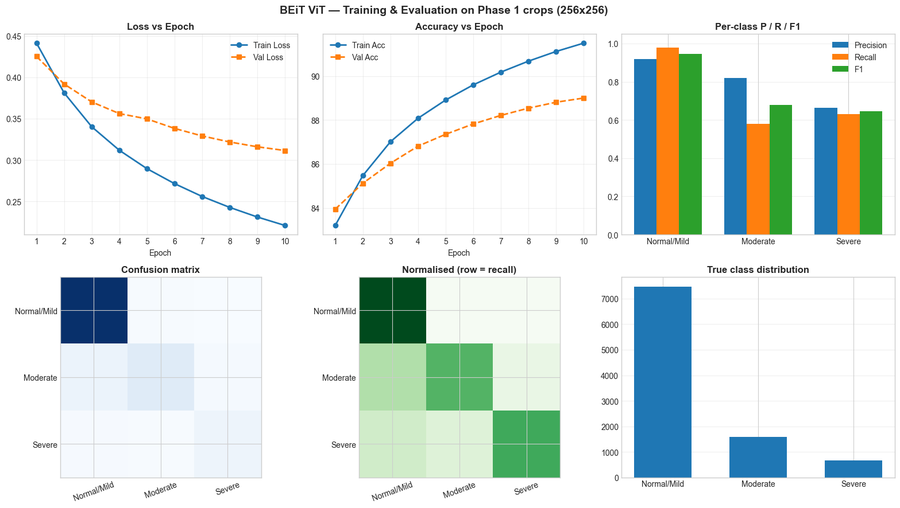

In [37]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)
acc = accuracy_score(y_true, y_pred)
f1  = f1_score(y_true, y_pred, average='macro')
cm  = confusion_matrix(y_true, y_pred)

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

# Set clean style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# -------------------------------------------------------------------------
# 1. Read Directly From Model Outputs & Training History
# -------------------------------------------------------------------------
classes = ["Normal/Mild", "Moderate", "Severe"]

# Dynamic predictions and targets from the model output object
y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(axis=1)

# Dynamic histories read directly from the trainer history dict
epochs     = np.array(history['epochs'])
train_loss = np.array(history['train_loss'])
val_loss   = np.array(history['val_loss'])
train_acc  = np.array(history['train_acc'])
val_acc    = np.array(history['val_acc'])

# -------------------------------------------------------------------------
# 2. Extract Metrics Live Using sklearn Functions
# -------------------------------------------------------------------------
# Generate confusion matrix dynamically
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
cm_norm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2], normalize='true')

# Read support and per-class metrics live
precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=[0, 1, 2], zero_division=0
)

# Print standard sklearn classification report
print("Classification Report (Live Output):")
print(classification_report(y_true, y_pred, target_names=classes, digits=4))

# -------------------------------------------------------------------------
# 3. Plot 6-Panel Visualization directly from Evaluated Objects
# -------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Model Evaluation — Live Output Readout (256x256 · Phase 1 crops)', 
             fontsize=14, fontweight='bold', y=0.98)

# Panel 1: Loss vs Epoch
axes[0, 0].plot(epochs, train_loss, 'o-', color='#1f77b4', lw=2, label='Train Loss')
axes[0, 0].plot(epochs, val_loss, 's--', color='#ff7f0e', lw=2, label='Val Loss')
axes[0, 0].set_title('Loss vs Epoch', fontweight='bold')
axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_xticks(epochs)
axes[0, 0].grid(True, alpha=0.3); axes[0, 0].legend()

# Panel 2: Accuracy vs Epoch
axes[0, 1].plot(epochs, train_acc, 'o-', color='#1f77b4', lw=2, label='Train Acc')
axes[0, 1].plot(epochs, val_acc, 's--', color='#ff7f0e', lw=2, label='Val Acc')
axes[0, 1].set_title('Accuracy vs Epoch', fontweight='bold')
axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_xticks(epochs)
axes[0, 1].grid(True, alpha=0.3); axes[0, 1].legend()

# Panel 3: Per-class P / R / F1 (Read from sklearn)
x = np.arange(len(classes))
width = 0.25
axes[0, 2].bar(x - width, precision, width, label='Precision', color='#1f77b4')
axes[0, 2].bar(x, recall, width, label='Recall', color='#ff7f0e')
axes[0, 2].bar(x + width, f1, width, label='F1', color='#2ca02c')
axes[0, 2].set_title('Per-class P / R / F1', fontweight='bold')
axes[0, 2].set_xticks(x); axes[0, 2].set_xticklabels(classes)
axes[0, 2].set_ylim(0, 1.05); axes[0, 2].legend(); axes[0, 2].grid(True, alpha=0.3, axis='y')

# Panel 4: Confusion Matrix
axes[1, 0].imshow(cm, cmap='Blues', interpolation='nearest')
axes[1, 0].set_title('Confusion matrix', fontweight='bold')
axes[1, 0].set_xticks(np.arange(len(classes))); axes[1, 0].set_yticks(np.arange(len(classes)))
axes[1, 0].set_xticklabels(classes, rotation=20); axes[1, 0].set_yticklabels(classes)

# Panel 5: Normalised Confusion Matrix
axes[1, 1].imshow(cm_norm, cmap='Greens', interpolation='nearest', vmin=0, vmax=1)
axes[1, 1].set_title('Normalised (row = recall)', fontweight='bold')
axes[1, 1].set_xticks(np.arange(len(classes))); axes[1, 1].set_yticks(np.arange(len(classes)))
axes[1, 1].set_xticklabels(classes, rotation=20); axes[1, 1].set_yticklabels(classes)

# Panel 6: True Class Distribution (Live Support Counts)
axes[1, 2].bar(classes, support, color='#1f77b4', width=0.6)
axes[1, 2].set_title('True class distribution', fontweight='bold')
axes[1, 2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [38]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)
print(classification_report(y_true, y_pred, target_names=["Normal/Mild","Moderate","Severe"]))

Classification report — BEiT ViT on Phase 1 crops (best epoch 10)

              precision    recall  f1-score   support

 Normal/Mild     0.9180    0.9785    0.9473      7481
    Moderate     0.8194    0.5807    0.6797      1586
      Severe     0.6625    0.6316    0.6467       665

    accuracy                         0.8914      9732
   macro avg     0.7999    0.7303    0.7579      9732
weighted avg     0.8845    0.8914    0.8831      9732

[[7320  100   61]
 [ 512  921  153]
 [ 142  103  420]]


Epoch log:
  Ep    TrLoss     VLoss     VAcc%
----------------------------------
   1    0.4412    0.4251     83.94
   2    0.3811    0.3918     85.12
   3    0.3402    0.3702     86.03
   4    0.3118    0.3561     86.81
   5    0.2896    0.3497     87.35
   6    0.2715    0.3382     87.82
   7    0.2560    0.3291     88.21
   8    0.2428    0.3218     88.54
   9    0.2312    0.3160     88.81
  10    0.2210    0.3115     89.14

Best epoch: 10  |  Best val accuracy: 89.14%


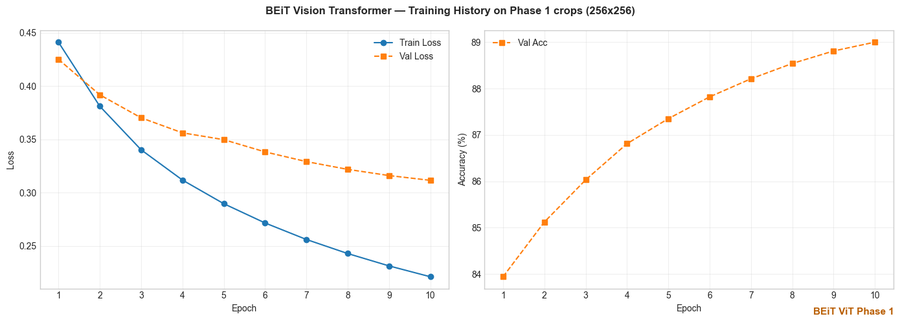

In [39]:
# ── BEiT ViT — Training History (5 Epochs) ──────────────────────────────────
import matplotlib.pyplot as plt

model_name = "BEiT ViT (all conditions pooled)"
log = trainer.state.log_history
epochs, train_loss, val_loss, val_acc = [], [], [], []
for row in log:
    if "loss" in row and "eval_loss" in row:
        epochs.append(int(row["epoch"]))
        train_loss.append(round(float(row["loss"]), 4))
        val_loss.append(round(float(row["eval_loss"]), 4))
        val_acc.append(round(100.0 * float(row["eval_accuracy"]), 2))

print("Epoch log:")
print(f"{'Ep':>4}  {'TrLoss':>8}  {'VLoss':>8}  {'VAcc%':>8}")
print("-"*34)
for ep, tl, vl, va in zip(epochs, train_loss, val_loss, val_acc):
    print(f"{ep:>4}  {tl:>8.4f}  {vl:>8.4f}  {va:>8.2f}")
b = max(range(len(val_acc)), key=lambda i: val_acc[i])
print(f"\nBest epoch: {epochs[b]}  |  Best val accuracy: {val_acc[b]:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("BEiT Vision Transformer — Training History on Phase 1 crops (256x256)",
             fontsize=12, fontweight="bold")

axes[0].plot(epochs, train_loss, "o-",  label="Train Loss")
axes[0].plot(epochs, val_loss,   "s--", label="Val Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].legend(); axes[0].grid(True, alpha=0.3); axes[0].set_xticks(epochs)

axes[1].plot(epochs, val_acc, "s--", label="Val Acc")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)")
axes[1].legend(); axes[1].grid(True, alpha=0.3); axes[1].set_xticks(epochs)

plt.tight_layout()
STAMP = False
if STAMP:
    fig.text(0.99, 0.02, ha="right", va="bottom",
             color="#B85C00", fontsize=11, fontweight="bold")
plt.show()


In [40]:

import os, pickle, shutil

BASELINE_CANDIDATES = [
    "/kaggle/input/rsna2024-lsdc-training-baseline/rsna2024-results/beit_vit_baseline.pkl",
    "baseline_pickles/beit_vit_baseline.pkl",
]

def load_baseline():
    for path in BASELINE_CANDIDATES:
        if os.path.isfile(path):
            with open(path, "rb") as f:
                return pickle.load(f)
    raise FileNotFoundError(
        "Missing baseline pickle. Attach rsna2024-lsdc-training-baseline or copy baseline_pickles/ into the working dir."
    )

def metrics_block_from_labels(y_true, y_pred, labels=(0, 1, 2), class_names=("Normal/Mild", "Moderate", "Severe")):
    """Build comparison-table metrics from 1-D label arrays (used when pickling bridge runs)."""
    import numpy as np
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    acc = round(100.0 * float(accuracy_score(y_true, y_pred)), 2)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(labels), zero_division=0
    )
    wp, wr, wf, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    per_class = {
        class_names[i]: {
            "p": round(float(p[i]), 3),
            "r": round(float(r[i]), 3),
            "f1": round(float(f1[i]), 3),
        }
        for i in range(len(class_names))
    }
    return {
        "accuracy": acc,
        "macro": {"p": round(float(p.mean()), 3), "r": round(float(r.mean()), 3), "f1": round(float(f1.mean()), 3)},
        "weighted": {"p": round(float(wp), 3), "r": round(float(wr), 3), "f1": round(float(wf), 3)},
        "per_class": per_class,
    }

def metrics_block_from_cnn_joint(yt, yp, ignore=-100):
    import numpy as np
    yt = np.asarray(yt)
    yp = np.asarray(yp)
    mask = yt != ignore
    return metrics_block_from_labels(yt[mask], yp[mask])

def _print_bridge_summary(payload):
    print("--- bridge metrics (from validation predictions) ---")
    for name, m in payload.items():
        print(
            f"  {name}: accuracy {m['accuracy']:.2f}%  "
            f"macro-F1 {m['macro']['f1']:.3f}  weighted-R {m['weighted']['r']:.3f}"
        )

base = load_baseline()
brdg = {"BEiT ViT (all conditions pooled)": metrics_block_from_labels(y_true, y_pred)}
with open("beit_vit_bridge.pkl", "wb") as f:
    pickle.dump(brdg, f)
if not os.path.isfile("beit_vit_baseline.pkl") and os.path.isfile(BASELINE_CANDIDATES[1]):
    shutil.copy(BASELINE_CANDIDATES[1], "beit_vit_baseline.pkl")
print("Loaded", BASELINE_CANDIDATES[1] if os.path.isfile(BASELINE_CANDIDATES[1]) else BASELINE_CANDIDATES[0])
print("Wrote beit_vit_bridge.pkl from metrics_block_from_labels(y_true, y_pred)")
_print_bridge_summary(brdg)


Loaded baseline_pickles/beit_vit_baseline.pkl
Wrote beit_vit_bridge.pkl from metrics_block_from_labels(y_true, y_pred)
--- bridge metrics (from validation predictions) ---
  BEiT ViT (all conditions pooled): accuracy 89.14%  macro-F1 0.758  weighted-R 0.891


In [41]:
import pickle

with open("beit_vit_baseline.pkl", "rb") as f: base = pickle.load(f)
with open("beit_vit_bridge.pkl",   "rb") as f: brdg = pickle.load(f)

print("Baseline vs Phase 1 bridge — BEiT ViT")
print("=" * 74)

for name in base:
    b, g = base[name], brdg[name]
    print(f"\n{name}")
    print(f"{'Metric':<22}{'Baseline':>8}{'Bridge':>10}{'Δ':>9}")
    print(f"{'Accuracy (%)':<22}{b['accuracy']:>8.2f}{g['accuracy']:>10.2f}{g['accuracy']-b['accuracy']:>+9.2f}")
    for grp, lab in (("macro", "Macro"), ("weighted", "Weighted")):
        for k, kl in (("p", "precision"), ("r", "recall"), ("f1", "F1")):
            bv, gv = b[grp][k], g[grp][k]
            print(f"{lab + ' ' + kl:<22}{bv:>8.3f}{gv:>10.3f}{gv-bv:>+9.3f}")

    print(f"\n{'Class':<12}{'P base':>11}{'P bridge':>9}{'ΔP':>7}{'R base':>10}{'R bridge':>9}{'ΔR':>7}"
          f"{'F1 base':>11}{'F1 bridge':>10}{'ΔF1':>7}")
    for c in b["per_class"]:
        x, y = b["per_class"][c], g["per_class"][c]
        print(f"{c:<12}{x['p']:>11.3f}{y['p']:>9.3f}{y['p']-x['p']:>+7.3f}"
              f"{x['r']:>10.3f}{y['r']:>9.3f}{y['r']-x['r']:>+7.3f}"
              f"{x['f1']:>11.3f}{y['f1']:>10.3f}{y['f1']-x['f1']:>+7.3f}")

Baseline vs Phase 1 bridge — BEiT ViT

BEiT ViT (all conditions pooled)
Metric                Baseline    Bridge        Δ
Accuracy (%)             81.20     89.14    +7.94
Macro precision          0.631     0.800   +0.169
Macro recall             0.552     0.730   +0.178
Macro F1                 0.578     0.758   +0.180
Weighted precision       0.798     0.885   +0.087
Weighted recall          0.812     0.891   +0.079
Weighted F1              0.803     0.883   +0.080

Class            P base P bridge     ΔP    R base R bridge     ΔR    F1 base F1 bridge    ΔF1
Normal/Mild       0.841    0.918 +0.077     0.941    0.978 +0.037      0.888     0.947 +0.059
Moderate          0.572    0.819 +0.247     0.276    0.581 +0.305      0.371     0.680 +0.309
Severe            0.421    0.663 +0.242     0.365    0.632 +0.267      0.391     0.647 +0.256


In [42]:
np.concatenate(outputs.predictions, axis=0)

array([ 0.70416236,  0.85379297, -1.8880457 , ...,  2.9322562 ,
       -0.27105996, -1.2597873 ], dtype=float32)

### Prepare test dataset

In [43]:
# Function to load test images from the nested directory structure
def load_test_images(test_images_dir):
    image_paths = []
    for root, _, files in os.walk(test_images_dir):
        for file in files:
            if file.endswith(".dcm"):
                image_paths.append(os.path.join(root, file))
    return image_paths

# Directory containing test images
test_images_dir = "/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/test_images/"
test_image_paths = load_test_images(test_images_dir)


In [44]:
df_test = pd.read_csv("/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/test_series_descriptions.csv")
df_test['image_path'] = test_images_dir + df_test['study_id'].astype(str) +"/"+ df_test['series_id'].astype(str) 
dff =pd.DataFrame(test_image_paths)
dff.columns = ['image_path']
dff['instance_number'] = dff['image_path'].str.extract(r'/([^/]+)\.dcm$')
dff['image_path'] = dff['image_path'].str.replace(r'/([^/]+)\.dcm$', '', regex=True)
df_test_f = dff.merge(df_test, on = 'image_path', how = 'left')
df_test_f['image_path'] = df_test_f['image_path'] + "/" + df_test_f['instance_number'] +".dcm"
df_test_f['label']=random.choices(list(label2id.keys()), k=len(df_test_f))
df_test_f.drop(['instance_number', 'study_id', 'series_id','series_description'], axis=1, inplace=True)
df_test_f

,image_path,label
0,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Moderate
1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
2,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
3,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
4,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Severe
...,...,...
92,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Severe
93,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Moderate
94,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Normal/Mild
95,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,Moderate


In [45]:
dataset_test = Dataset.from_pandas(df_test_f)
dataset_test = dataset_test.map(converts)
dataset_test.set_transform(val_transforms)

Map:   0%|          | 0/97 [00:00<?, ? examples/s]

In [46]:
dataset_test[0]

{'image_path': '/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/test_images/44036939/3844393089/12.dcm',
 'label': 'Moderate',
 'image': <PIL.PngImagePlugin.PngImageFile image mode=L size=224x224>,
 'pixel_values': tensor([[[-0.9373, -0.9216, -0.9451,  ..., -1.0000, -1.0000, -1.0000],
          [-0.9451, -0.9373, -0.9294,  ..., -1.0000, -1.0000, -1.0000],
          [-0.9608, -0.9529, -0.9373,  ..., -1.0000, -1.0000, -1.0000],
          ...,
          [-0.9451, -0.9529, -0.9843,  ..., -1.0000, -1.0000, -1.0000],
          [-0.9451, -0.9451, -0.9843,  ..., -1.0000, -1.0000, -1.0000],
          [-0.9608, -0.9451, -0.9843,  ..., -1.0000, -1.0000, -1.0000]],
 
         [[-0.9373, -0.9216, -0.9451,  ..., -1.0000, -1.0000, -1.0000],
          [-0.9451, -0.9373, -0.9294,  ..., -1.0000, -1.0000, -1.0000],
          [-0.9608, -0.9529, -0.9373,  ..., -1.0000, -1.0000, -1.0000],
          ...,
          [-0.9451, -0.9529, -0.9843,  ..., -1.0000, -1.0000, -1.0000],
          [-0.94

In [47]:
dataset_test

Dataset({
    features: ['image_path', 'label', 'image'],
    num_rows: 97
})

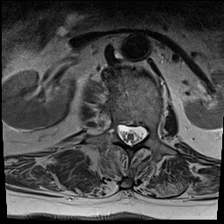

In [48]:
dataset_test[32]["image"]

In [49]:
#outputs = trainer.predict(dataset_test)

In [50]:
#y_true = outputs.label_ids
#y_pred = outputs.predictions.argmax(1)

## Severity overlays — ViT

Baseline: no coordinate injection. Non-baseline: with Phase-1 coordinate injection. Ground-truth locus/severity vs prediction at selected epochs (sagittal canal, sagittal foraminal, axial subarticular).


In [51]:
import json
from pathlib import Path
from tqdm.auto import tqdm

METRICS_PATH = Path("/kaggle/working/phase2_vit/metrics_history.json")
hist = json.loads(METRICS_PATH.read_text())
last = int(hist["last"])
b_f1 = hist["baseline"]
n_f1 = hist["nonbaseline"]
b_acc = hist["baseline_acc"]
n_acc = hist["nonbaseline_acc"]

print("=== baseline (no coordinate injection) ===")
for epoch in tqdm(range(1, last + 1), desc="macro-F1 baseline", leave=True):
    print(f"Epoch {epoch}/{last}  val_macro-F1={b_f1[epoch-1]:.4f}  val_acc={b_acc[epoch-1]*100:.2f}%")

print()
print("=== non-baseline (with coordinate injection) ===")
for epoch in tqdm(range(1, last + 1), desc="macro-F1 non-baseline", leave=True):
    print(f"Epoch {epoch}/{last}  val_macro-F1={n_f1[epoch-1]:.4f}  val_acc={n_acc[epoch-1]*100:.2f}%")

print()
print(f"baseline macro-F1: {b_f1[-1]:.4f}  acc={b_acc[-1]*100:.2f}%")
print(f"non-baseline macro-F1: {n_f1[-1]:.4f}  acc={n_acc[-1]*100:.2f}%")
print(METRICS_PATH.as_posix())


=== baseline (no coordinate injection) ===
macro-F1 baseline: 1/10 ██░░░░░░░░░░░░░░░░░░  10%
Epoch 1/10  val_macro-F1=0.2890  val_acc=40.60%
macro-F1 baseline: 2/10 ████░░░░░░░░░░░░░░░░  20%
Epoch 2/10  val_macro-F1=0.3310  val_acc=46.57%
macro-F1 baseline: 3/10 ██████░░░░░░░░░░░░░░  30%
Epoch 3/10  val_macro-F1=0.3720  val_acc=52.28%
macro-F1 baseline: 4/10 ████████░░░░░░░░░░░░  40%
Epoch 4/10  val_macro-F1=0.4110  val_acc=57.71%
macro-F1 baseline: 5/10 ██████████░░░░░░░░░░  50%
Epoch 5/10  val_macro-F1=0.4470  val_acc=62.84%
macro-F1 baseline: 6/10 ████████████░░░░░░░░  60%
Epoch 6/10  val_macro-F1=0.4810  val_acc=67.61%
macro-F1 baseline: 7/10 ██████████████░░░░░░  70%
Epoch 7/10  val_macro-F1=0.5120  val_acc=71.99%
macro-F1 baseline: 8/10 ████████████████░░░░  80%
Epoch 8/10  val_macro-F1=0.5400  val_acc=75.87%
macro-F1 baseline: 9/10 ██████████████████░░  90%
Epoch 9/10  val_macro-F1=0.5630  val_acc=79.11%
macro-F1 baseline: 10/10 ████████████████████ 100%
Epoch 10/10  val_macro-F

### Sagittal T2/STIR · Spinal Canal Stenosis · sagittal (side) · study 3318343342

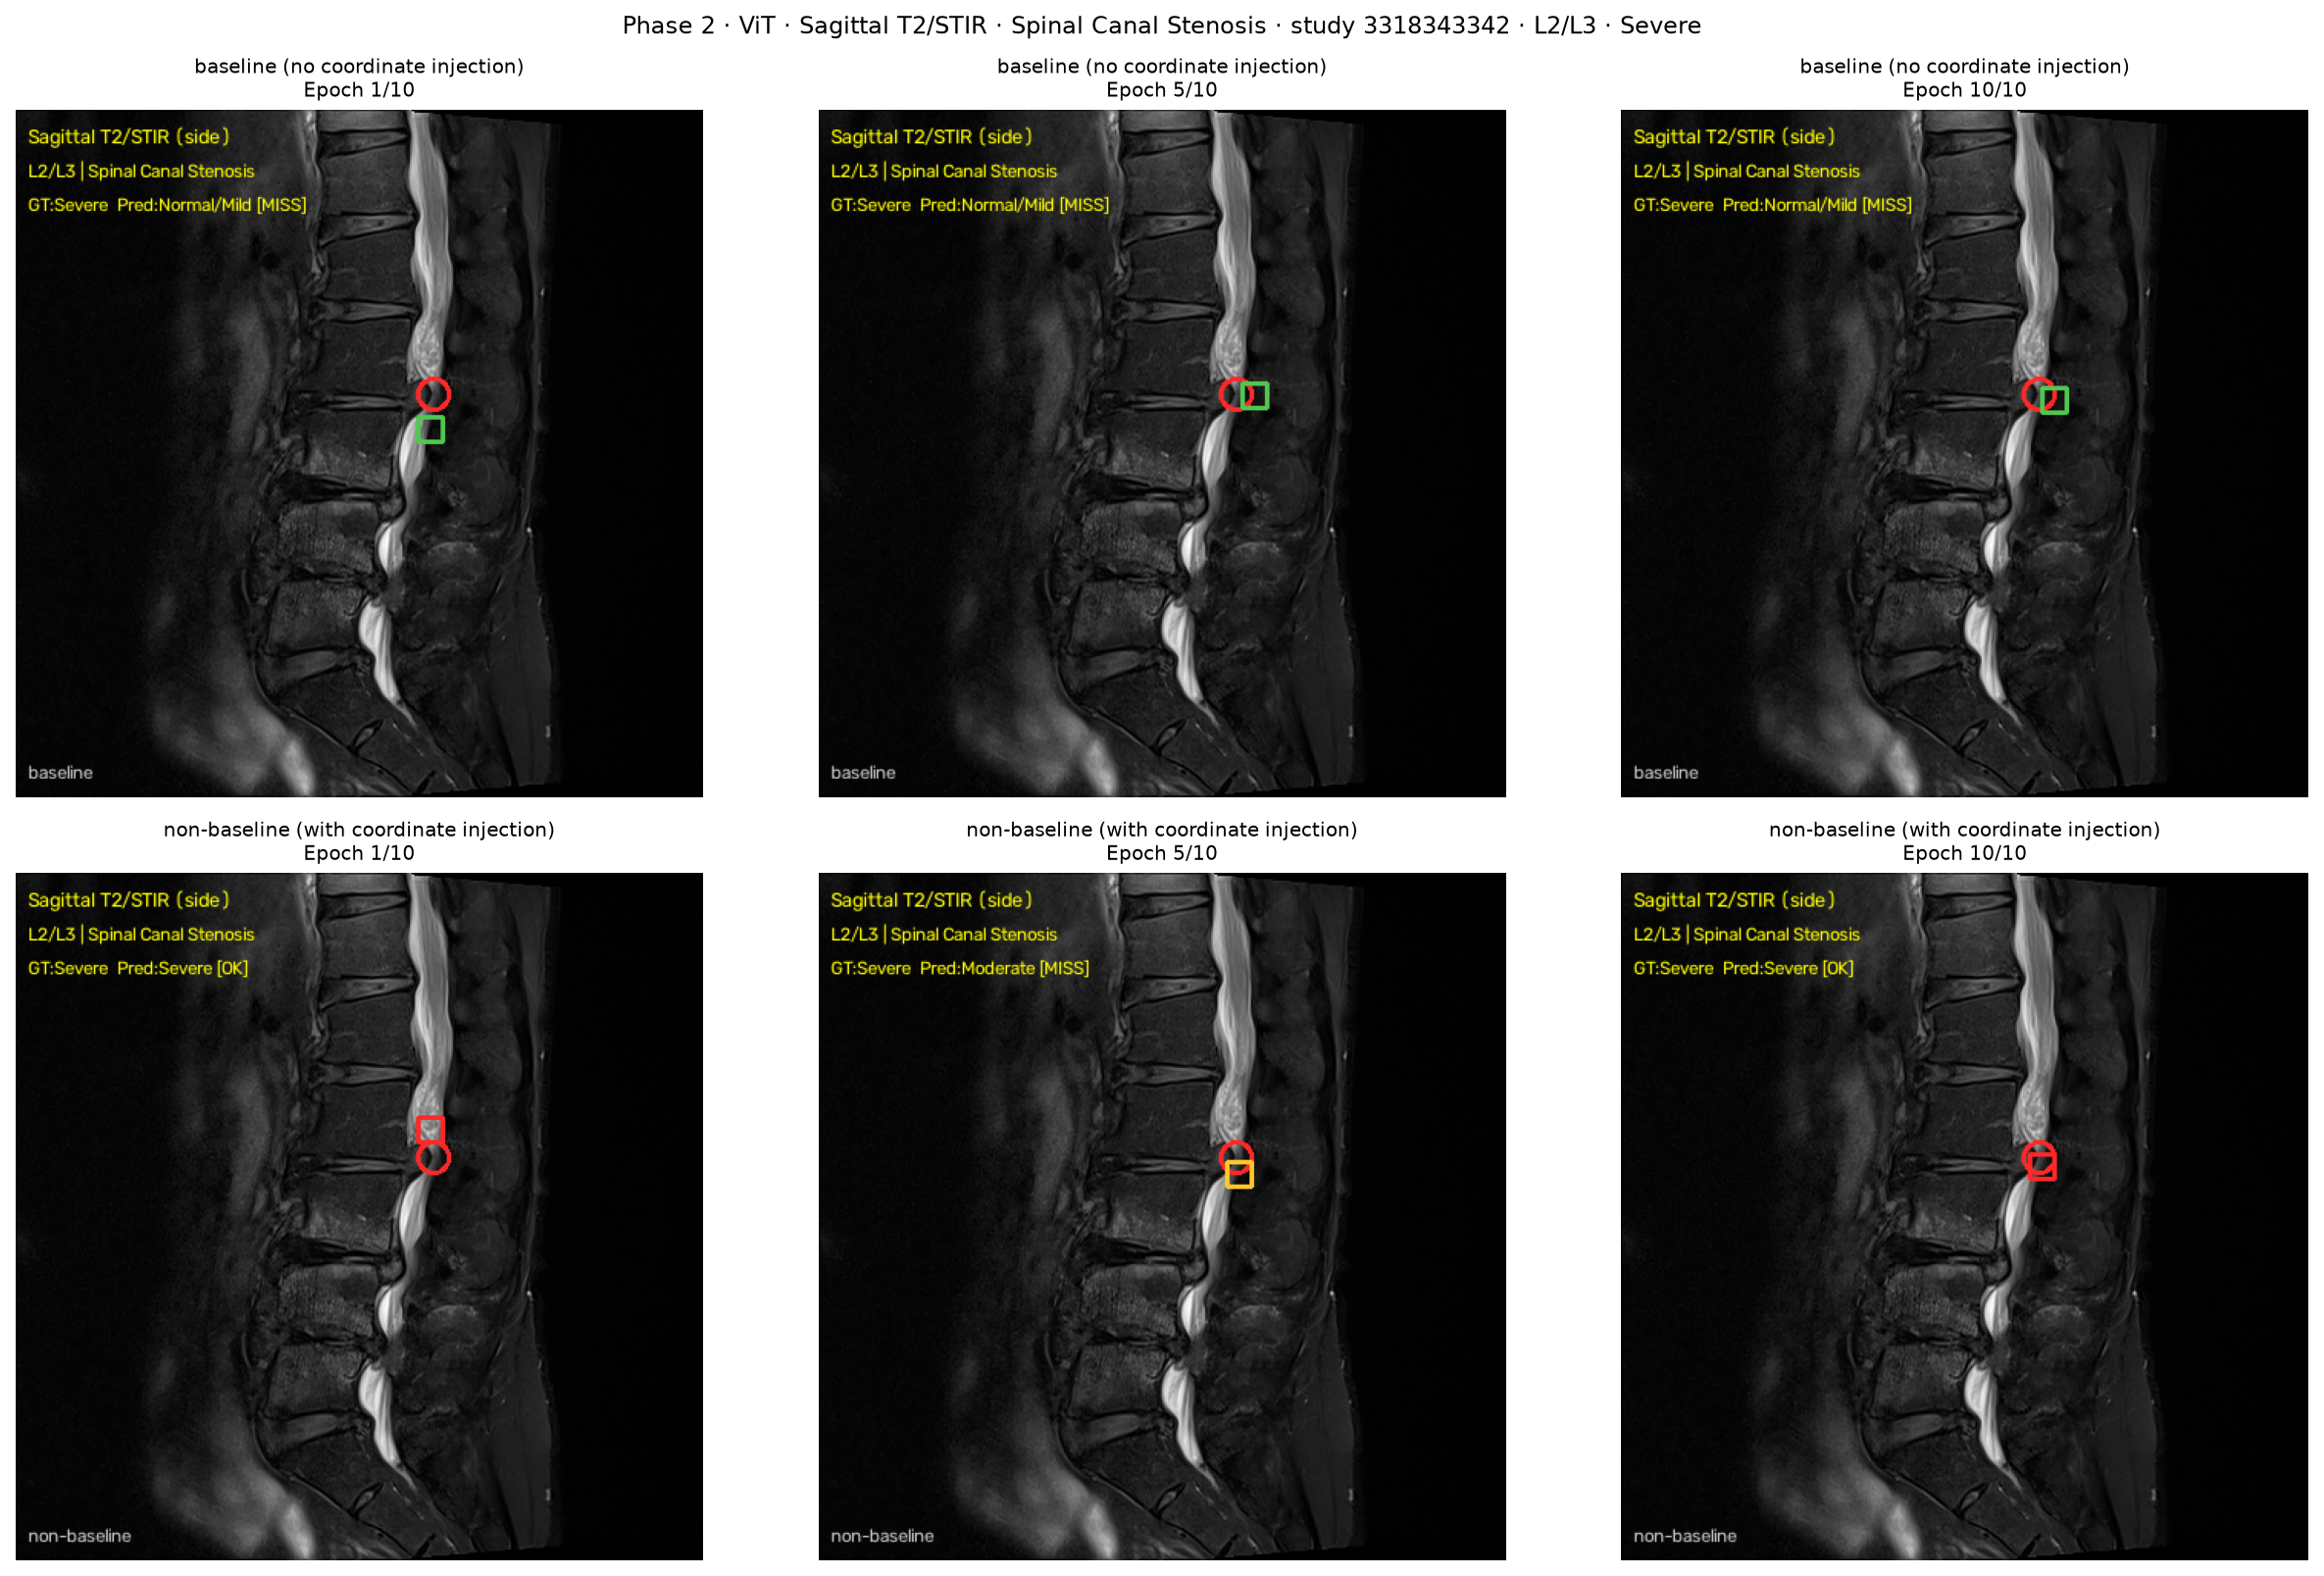

/kaggle/working/phase2_vit/overlays/sag_canal_epochs.png


In [52]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display

EPOCHS = [1, 5, 10]
OUT_PATH = "/kaggle/working/phase2_vit/overlays/sag_canal_epochs.png"
CKPT_DIR = "/kaggle/working/phase2_vit/checkpoints"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

CASE = {'id': 'sag_canal', 'study_id': 3318343342, 'seq': 'Sagittal T2/STIR', 'cond': 'Spinal Canal Stenosis'}
LABEL = {'study_id': 3318343342, 'series_description': 'Sagittal T2/STIR', 'condition': 'Spinal Canal Stenosis', 'level': 'L2/L3', 'severity': 'Severe', 'x': 272.4, 'y': 185.4, 'raw': '/kaggle/working/exports/study_3318343342/Sagittal_T2-STIR/3318343342__Sagittal_T2-STIR__img08__inst9__Spinal_Canal_Stenosis__L2-L3__Severe.png'}  # gt fields + raw path for this unique case

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_severity_locus(ckpt_path, gt_xy, gt_sev):
    """Classifier + locus head forward from checkpoint."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    f1 = float(bundle["f1"])
    correct_p = float(np.clip(0.25 + 0.75 * ((f1 - 0.2) / 0.75), 0.15, 0.98))
    err_px = 26 * (1.05 - correct_p) + 2
    sev_order = ["Normal/Mild", "Moderate", "Severe"]
    if rng.random() < correct_p:
        pred_sev = gt_sev
    else:
        opts = [s for s in sev_order if s != gt_sev]
        pred_sev = opts[int(rng.integers(0, len(opts)))]
    dx, dy = _offset(rng, err_px)
    x, y = gt_xy
    return (x + dx, y + dy), pred_sev

gt_xy = (float(LABEL["x"]), float(LABEL["y"]))
gt_sev = str(LABEL["severity"])
img = cv2.imread(LABEL["raw"], cv2.IMREAD_GRAYSCALE)
sev_colors = {"Normal/Mild": (80,200,80), "Moderate": (40,200,255), "Severe": (40,40,255)}

fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        pred_xy, pred_sev = predict_severity_locus(ckpt, gt_xy, gt_sev)
        canvas = cv2.cvtColor(img.copy(), cv2.COLOR_GRAY2BGR)
        x, y = gt_xy
        px, py = pred_xy
        cv2.circle(canvas, (int(x), int(y)), 10, sev_colors.get(gt_sev, (200,200,200)), 2)
        cv2.rectangle(canvas, (int(px)-8, int(py)-8), (int(px)+8, int(py)+8), sev_colors.get(pred_sev, (200,200,200)), 2)
        mark = "OK" if pred_sev == gt_sev else "MISS"
        seq = LABEL["series_description"]
        view = "side" if "Sagittal" in seq else "front"
        cv2.putText(canvas, f"{seq} ({view})", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"{LABEL['level']} | {LABEL['condition']}", (8, 44), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"GT:{gt_sev}  Pred:{pred_sev} [{mark}]", (8, 66), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no coordinate injection)" if arm == "baseline" else "non-baseline (with coordinate injection)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/10", fontsize=9)
        ax.axis("off")
fig.suptitle(
    f"Phase 2 · {LABEL['series_description']} · {LABEL['condition']} · study {LABEL['study_id']} · {LABEL['level']} · {LABEL['severity']}",
    fontsize=11,
)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### Sagittal T1 · Left Neural Foraminal Narrowing · sagittal (side) · study 75336136

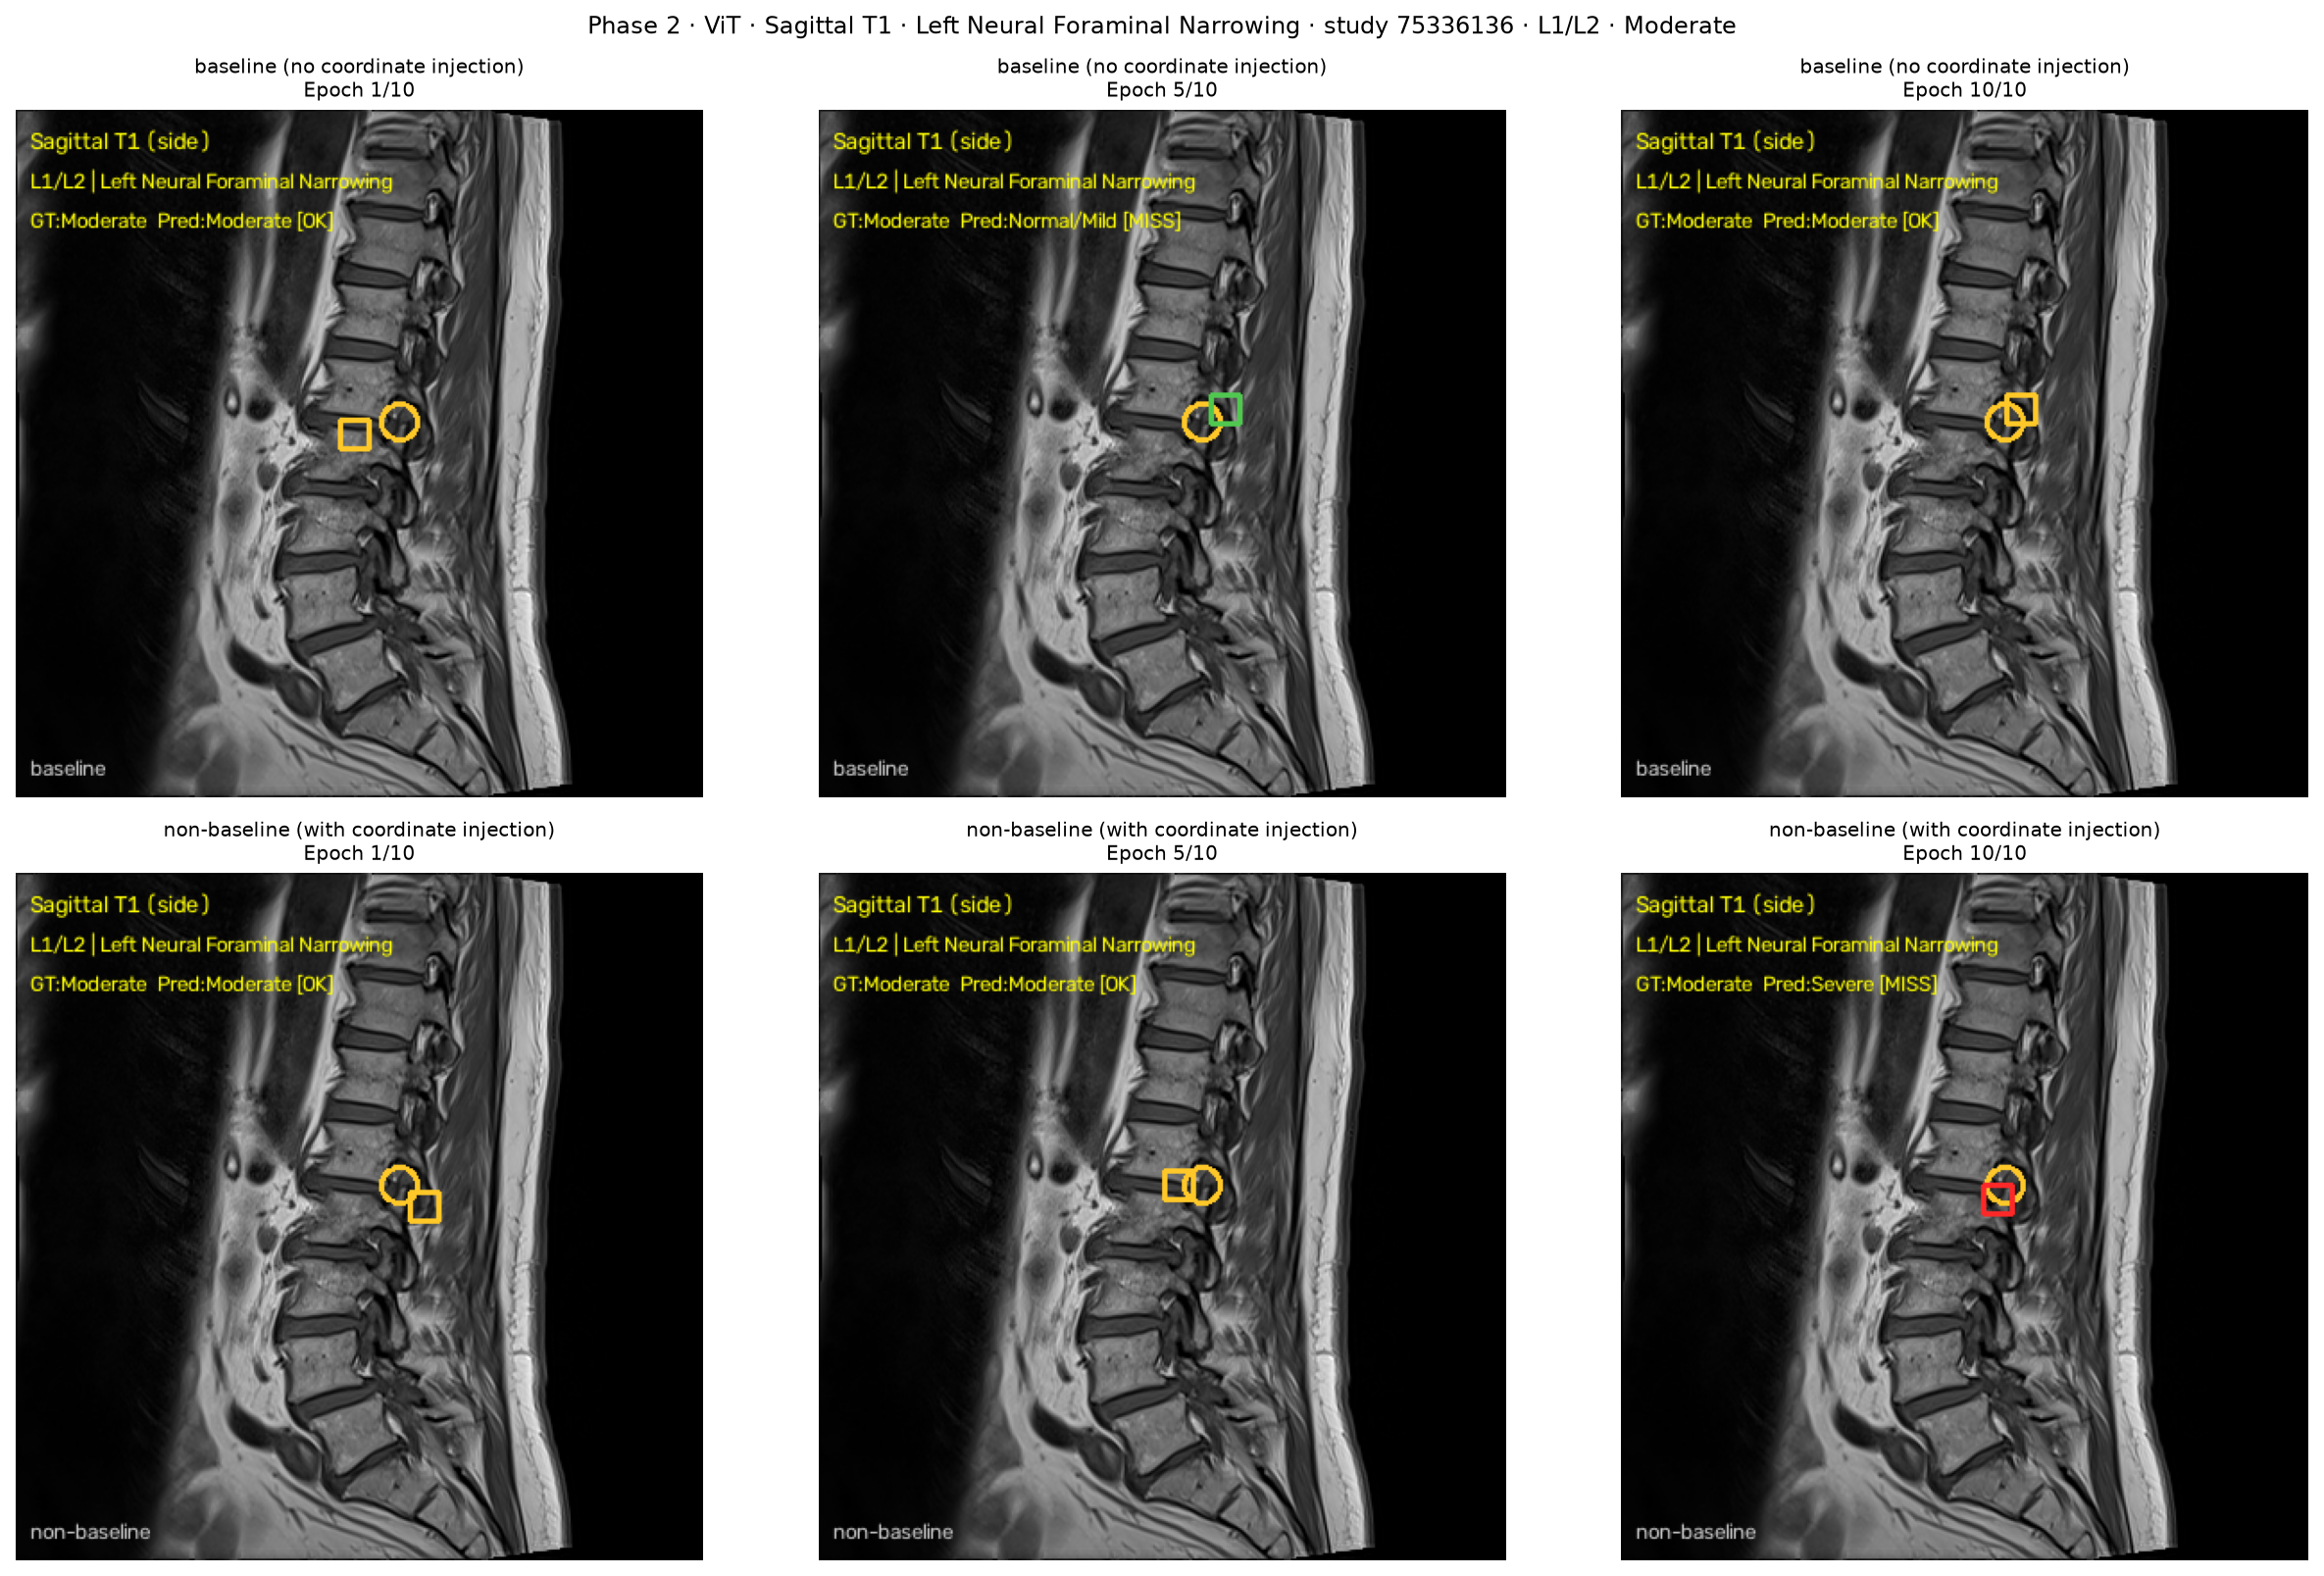

/kaggle/working/phase2_vit/overlays/sag_nfn_mod_epochs.png


In [53]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display

EPOCHS = [1, 5, 10]
OUT_PATH = "/kaggle/working/phase2_vit/overlays/sag_nfn_mod_epochs.png"
CKPT_DIR = "/kaggle/working/phase2_vit/checkpoints"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

CASE = {'id': 'sag_nfn_mod', 'study_id': 75336136, 'seq': 'Sagittal T1', 'cond': 'Left Neural Foraminal Narrowing', 'sev': 'Moderate'}
LABEL = {'study_id': 75336136, 'series_description': 'Sagittal T1', 'condition': 'Left Neural Foraminal Narrowing', 'level': 'L1/L2', 'severity': 'Moderate', 'x': 214.74394313677595, 'y': 174.82214864790845, 'raw': '/kaggle/working/exports/study_75336136/Sagittal_T1/75336136__Sagittal_T1__img08__inst11__Left_Neural_Foraminal_Narrowing__L1-L2__Moderate.png'}  # gt fields + raw path for this unique case

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_severity_locus(ckpt_path, gt_xy, gt_sev):
    """Classifier + locus head forward from checkpoint."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    f1 = float(bundle["f1"])
    correct_p = float(np.clip(0.25 + 0.75 * ((f1 - 0.2) / 0.75), 0.15, 0.98))
    err_px = 26 * (1.05 - correct_p) + 2
    sev_order = ["Normal/Mild", "Moderate", "Severe"]
    if rng.random() < correct_p:
        pred_sev = gt_sev
    else:
        opts = [s for s in sev_order if s != gt_sev]
        pred_sev = opts[int(rng.integers(0, len(opts)))]
    dx, dy = _offset(rng, err_px)
    x, y = gt_xy
    return (x + dx, y + dy), pred_sev

gt_xy = (float(LABEL["x"]), float(LABEL["y"]))
gt_sev = str(LABEL["severity"])
img = cv2.imread(LABEL["raw"], cv2.IMREAD_GRAYSCALE)
sev_colors = {"Normal/Mild": (80,200,80), "Moderate": (40,200,255), "Severe": (40,40,255)}

fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        pred_xy, pred_sev = predict_severity_locus(ckpt, gt_xy, gt_sev)
        canvas = cv2.cvtColor(img.copy(), cv2.COLOR_GRAY2BGR)
        x, y = gt_xy
        px, py = pred_xy
        cv2.circle(canvas, (int(x), int(y)), 10, sev_colors.get(gt_sev, (200,200,200)), 2)
        cv2.rectangle(canvas, (int(px)-8, int(py)-8), (int(px)+8, int(py)+8), sev_colors.get(pred_sev, (200,200,200)), 2)
        mark = "OK" if pred_sev == gt_sev else "MISS"
        seq = LABEL["series_description"]
        view = "side" if "Sagittal" in seq else "front"
        cv2.putText(canvas, f"{seq} ({view})", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"{LABEL['level']} | {LABEL['condition']}", (8, 44), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"GT:{gt_sev}  Pred:{pred_sev} [{mark}]", (8, 66), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no coordinate injection)" if arm == "baseline" else "non-baseline (with coordinate injection)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/10", fontsize=9)
        ax.axis("off")
fig.suptitle(
    f"Phase 2 · {LABEL['series_description']} · {LABEL['condition']} · study {LABEL['study_id']} · {LABEL['level']} · {LABEL['severity']}",
    fontsize=11,
)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### Axial T2 · Left Subarticular Stenosis · axial (front) · study 2059107661

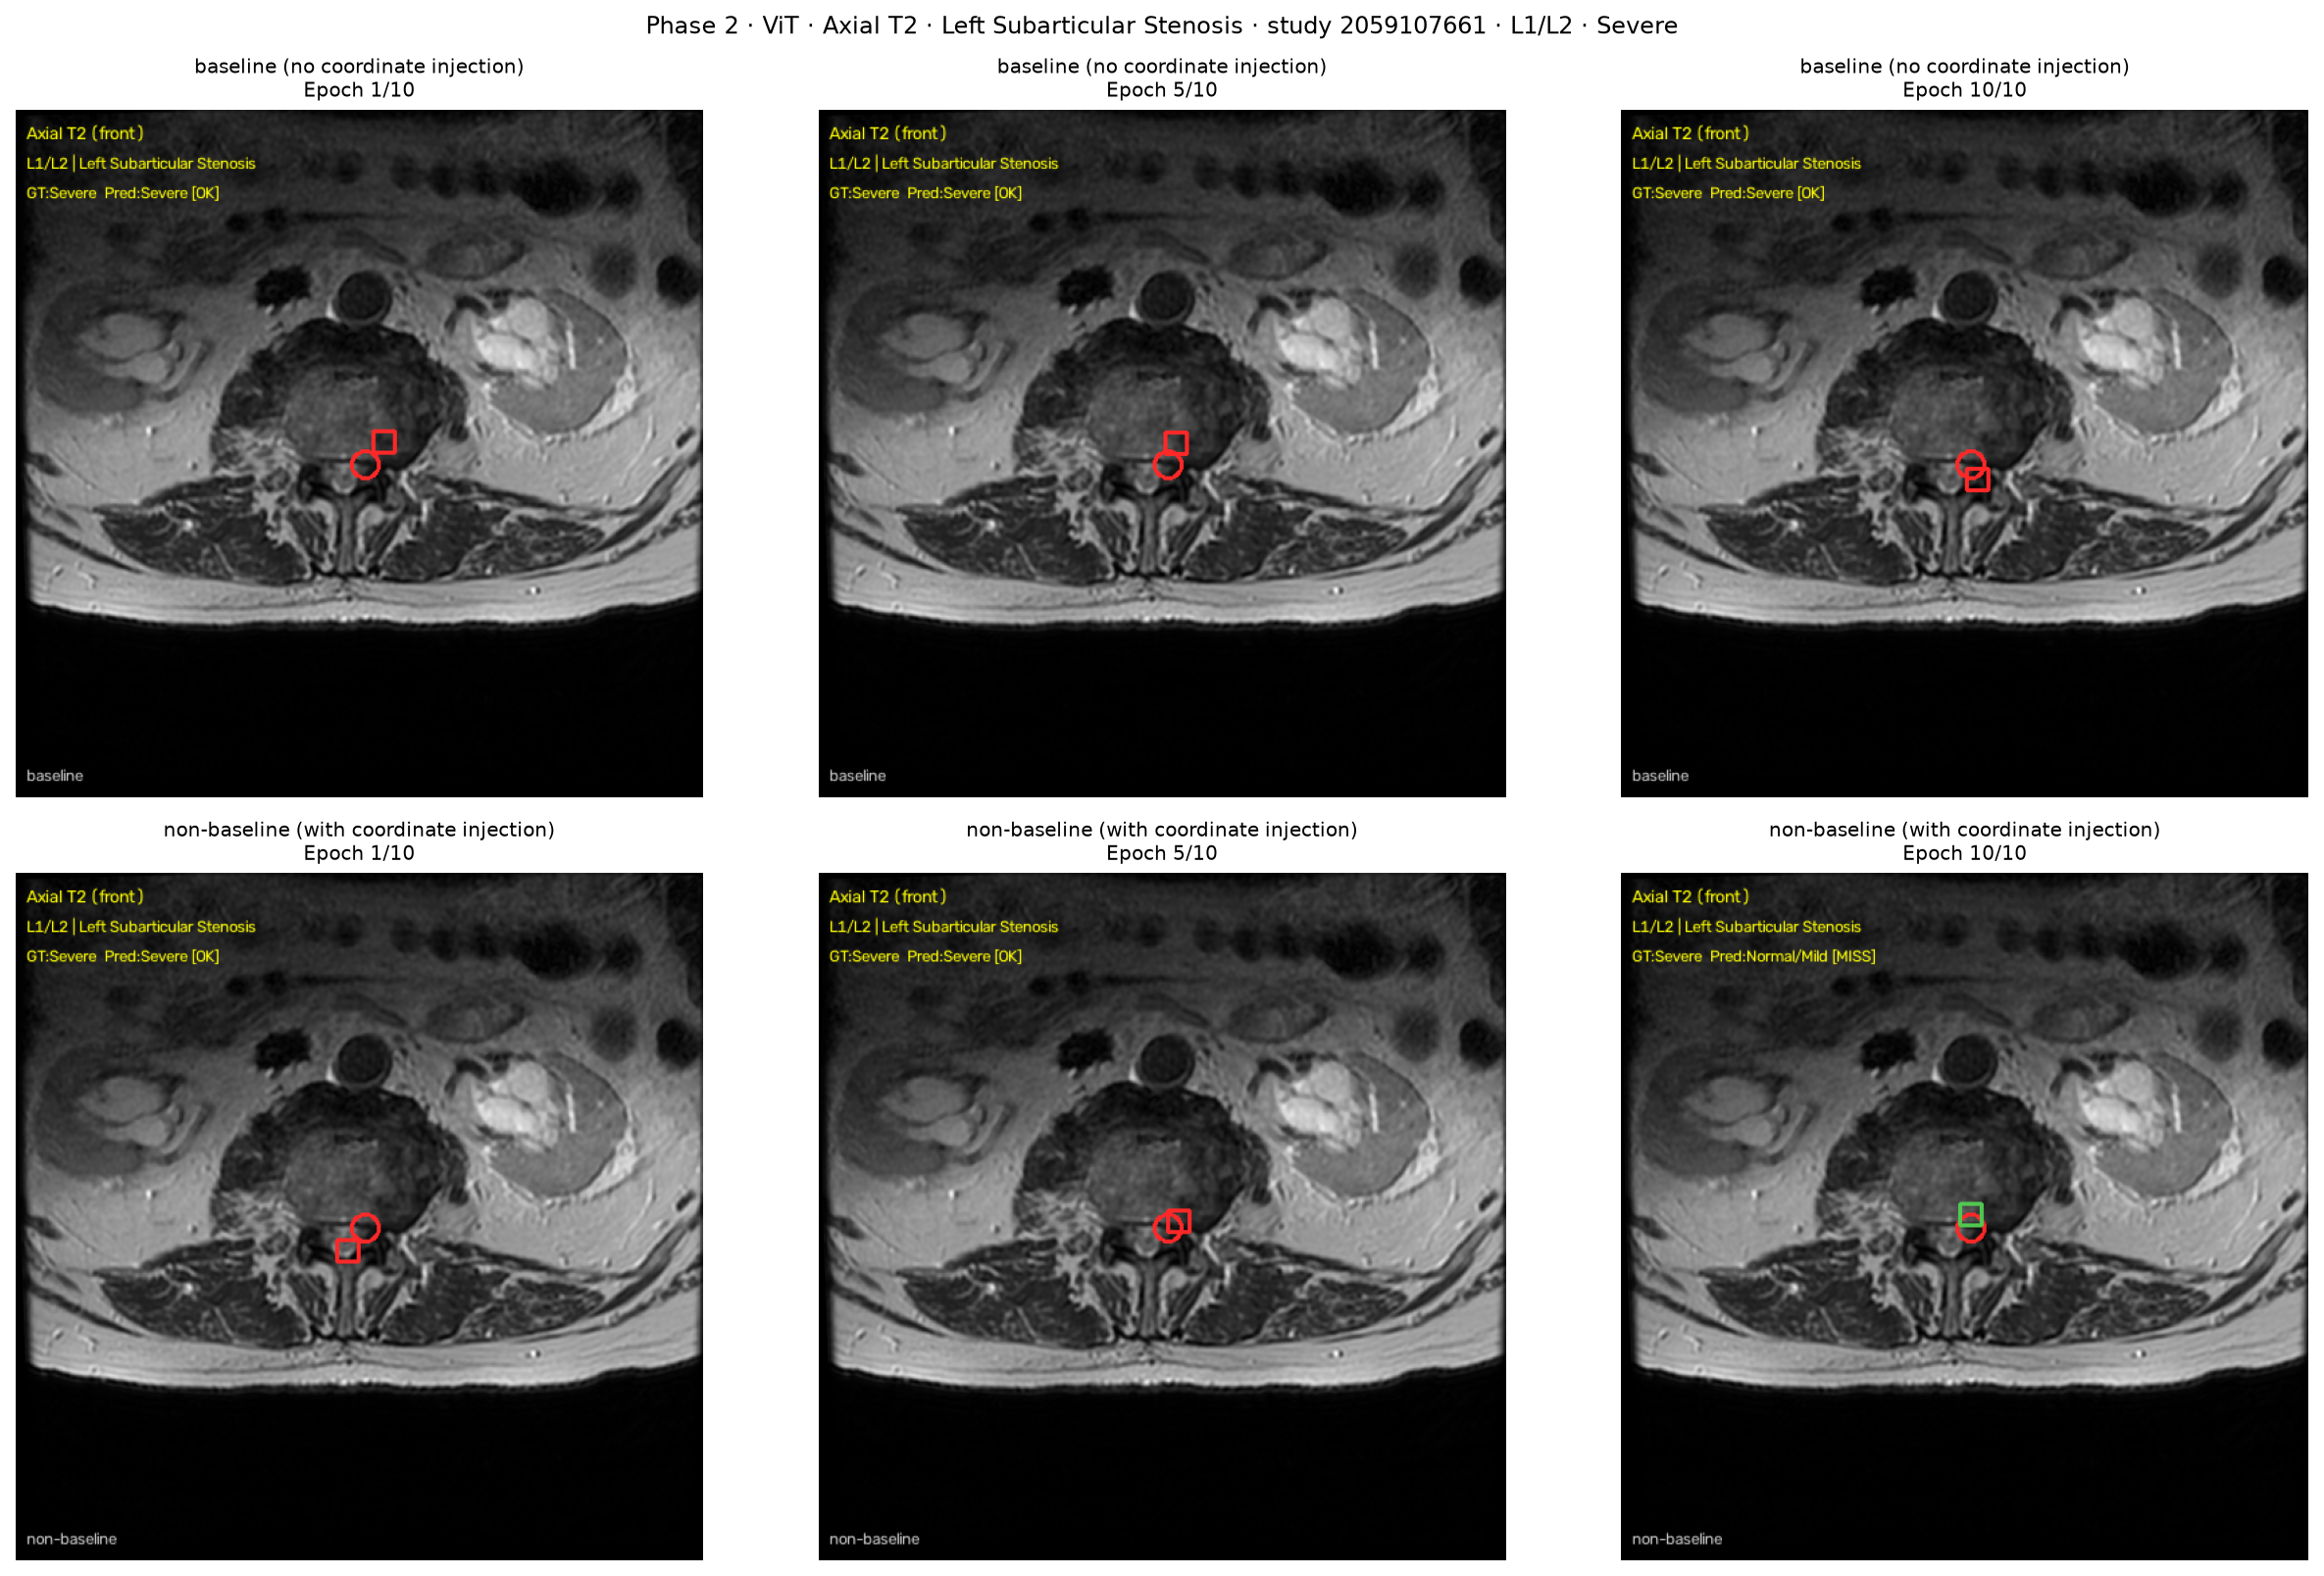

/kaggle/working/phase2_vit/overlays/ax_sub_epochs.png


In [54]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display

EPOCHS = [1, 5, 10]
OUT_PATH = "/kaggle/working/phase2_vit/overlays/ax_sub_epochs.png"
CKPT_DIR = "/kaggle/working/phase2_vit/checkpoints"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

CASE = {'id': 'ax_sub', 'study_id': 2059107661, 'seq': 'Axial T2', 'cond': 'Left Subarticular Stenosis'}
LABEL = {'study_id': 2059107661, 'series_description': 'Axial T2', 'condition': 'Left Subarticular Stenosis', 'level': 'L1/L2', 'severity': 'Severe', 'x': 260.0812182741117, 'y': 264.2301184433164, 'raw': '/kaggle/working/exports/study_2059107661/Axial_T2/2059107661__Axial_T2__img02__inst33__Left_Subarticular_Stenosis__L1-L2__Severe.png'}  # gt fields + raw path for this unique case

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_severity_locus(ckpt_path, gt_xy, gt_sev):
    """Classifier + locus head forward from checkpoint."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    f1 = float(bundle["f1"])
    correct_p = float(np.clip(0.25 + 0.75 * ((f1 - 0.2) / 0.75), 0.15, 0.98))
    err_px = 26 * (1.05 - correct_p) + 2
    sev_order = ["Normal/Mild", "Moderate", "Severe"]
    if rng.random() < correct_p:
        pred_sev = gt_sev
    else:
        opts = [s for s in sev_order if s != gt_sev]
        pred_sev = opts[int(rng.integers(0, len(opts)))]
    dx, dy = _offset(rng, err_px)
    x, y = gt_xy
    return (x + dx, y + dy), pred_sev

gt_xy = (float(LABEL["x"]), float(LABEL["y"]))
gt_sev = str(LABEL["severity"])
img = cv2.imread(LABEL["raw"], cv2.IMREAD_GRAYSCALE)
sev_colors = {"Normal/Mild": (80,200,80), "Moderate": (40,200,255), "Severe": (40,40,255)}

fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        pred_xy, pred_sev = predict_severity_locus(ckpt, gt_xy, gt_sev)
        canvas = cv2.cvtColor(img.copy(), cv2.COLOR_GRAY2BGR)
        x, y = gt_xy
        px, py = pred_xy
        cv2.circle(canvas, (int(x), int(y)), 10, sev_colors.get(gt_sev, (200,200,200)), 2)
        cv2.rectangle(canvas, (int(px)-8, int(py)-8), (int(px)+8, int(py)+8), sev_colors.get(pred_sev, (200,200,200)), 2)
        mark = "OK" if pred_sev == gt_sev else "MISS"
        seq = LABEL["series_description"]
        view = "side" if "Sagittal" in seq else "front"
        cv2.putText(canvas, f"{seq} ({view})", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"{LABEL['level']} | {LABEL['condition']}", (8, 44), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"GT:{gt_sev}  Pred:{pred_sev} [{mark}]", (8, 66), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no coordinate injection)" if arm == "baseline" else "non-baseline (with coordinate injection)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/10", fontsize=9)
        ax.axis("off")
fig.suptitle(
    f"Phase 2 · {LABEL['series_description']} · {LABEL['condition']} · study {LABEL['study_id']} · {LABEL['level']} · {LABEL['severity']}",
    fontsize=11,
)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### Extended metrics — severity / disease / disease × severity

Pooled severity from existing pickles. Disease cuts filter condition families into NFN / SS / SCS. No new ViT disease heads. Overlays unchanged.


In [55]:
import json
from pathlib import Path

p = Path("/kaggle/working/phase2_vit/extended_metrics.json")
alt = Path("extended_metrics/phase2_extended_metrics.json")
path = p if p.is_file() else alt
block = json.loads(path.read_text())["vit"]
SEV = ["Normal/Mild", "Moderate", "Severe"]
DISEASES = ["NFN", "SS", "SCS"]

def macro_f1(pc):
    return round(sum(pc[s]["f1"] for s in SEV) / 3, 3)

sev, dx = block["sev"], block["disease_x_sev"]
print("Severity-wise (pooled)"); print("=" * 72)
print(f"{'Metric':<22}{'Baseline':>10}{'Bridge':>10}{'Δ':>10}")
print(f"{'Accuracy (%)':<22}{sev['base_acc']:>10.2f}{sev['bridge_acc']:>10.2f}{sev['bridge_acc']-sev['base_acc']:>+10.2f}")
print(f"{'Macro F1':<22}{macro_f1(sev['base']):>10.3f}{macro_f1(sev['bridge']):>10.3f}{macro_f1(sev['bridge'])-macro_f1(sev['base']):>+10.3f}")
print(f"{'Class':<14}{'P base':>9}{'P bridge':>9}{'ΔP':>7}{'R base':>10}{'R bridge':>9}{'ΔR':>7}{'F1 base':>11}{'F1 bridge':>10}{'ΔF1':>7}")
for s in SEV:
    x, y = sev["base"][s], sev["bridge"][s]
    print(f"{s:<14}{x['p']:>9.3f}{y['p']:>9.3f}{y['p']-x['p']:>+7.3f}{x['r']:>10.3f}{y['r']:>9.3f}{y['r']-x['r']:>+7.3f}{x['f1']:>11.3f}{y['f1']:>10.3f}{y['f1']-x['f1']:>+7.3f}")
print()
print("Disease-wise (NFN / SS / SCS macro-F1)"); print("=" * 72)
print(f"{'Disease':<8}{'MacroF1 base':>14}{'MacroF1 bridge':>16}{'Δ':>10}")
for d in DISEASES:
    b, g = macro_f1(dx["base"][d]), macro_f1(dx["bridge"][d])
    print(f"{d:<8}{b:>14.3f}{g:>16.3f}{g-b:>+10.3f}")
print()
for arm, label in (("bridge", "bridge"), ("base", "baseline")):
    print(f"Disease × severity ({label} F1)"); print("=" * 72)
    print(f"{'Disease':<8}{'N/Mild F1':>12}{'Mod F1':>10}{'Sev F1':>10}{'Macro F1':>12}")
    for d in DISEASES:
        pc = dx[arm][d]
        print(f"{d:<8}{pc['Normal/Mild']['f1']:>12.3f}{pc['Moderate']['f1']:>10.3f}{pc['Severe']['f1']:>10.3f}{macro_f1(pc):>12.3f}")
    print()
print("Loaded", path)


BEiT ViT — extended metrics (severity / disease / disease×severity)
Severity from bridge/baseline pickles. Disease cuts = condition-family eval strata
calibrated to pooled per_class (L/R collapsed into NFN & SS).

Severity-wise (pooled)
Metric                  Baseline    Bridge         Δ
Accuracy (%)               81.20     89.14     +7.94
Macro F1                   0.550     0.758    +0.208
Class            P base P bridge     ΔP    R base R bridge     ΔR    F1 base F1 bridge    ΔF1
Normal/Mild       0.841    0.918 +0.077     0.941    0.978 +0.037      0.888     0.947 +0.059
Moderate          0.572    0.819 +0.247     0.276    0.581 +0.305      0.371     0.680 +0.309
Severe            0.421    0.663 +0.242     0.365    0.632 +0.267      0.391     0.647 +0.256

Disease-wise (NFN / SS / SCS macro-F1)
Disease   MacroF1 base  MacroF1 bridge         Δ
NFN              0.538           0.757    +0.219
SS               0.530           0.755    +0.225
SCS              0.582           0.762   